<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/opencv%2Brf-(spacing)/spacing_rf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sinhala Word Spacing Detection — Random Forest
**Gap measurement + Random Forest classifier**

1. Setup and load the dataset from Google Drive
2. Split into **train / validation / test** (70 / 15 / 15, stratified)
3. Preprocessing: **grayscale** → lighting correction → binarization → ruled-line removal → noise removal
4. Measure gaps between words and build scale-free features
5. Check the gap detection visually
6. Tune Random Forest (depth, leaf size, features per split) on **train** with cross-validation, check on **validation**
7. Final evaluation on **test**: all metrics with 95% CIs, **confusion matrices**, ROC / PR / calibration curves, feature importance
7b. More evaluation: repeated 10-fold CV, learning curve, threshold analysis, permutation test, permutation importance
8. Save the model
9. **Predict a new handwriting image**

All results are saved to `My Drive/dataset2/random_forest_output/`. Run the cells from top to bottom.

In [ ]:
# ===== 1. Setup =====

from google.colab import drive
drive.mount('/content/drive')

import os, glob, json, random, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

# Folder that contains "good spacing" and "bad spacing".
# Colab left sidebar → Files → drive → MyDrive → find the folder → ⋮ → "Copy path", paste below.
# (If the folder is in "Shared with me": in Google Drive right-click it → Organize → Add shortcut → My Drive.)
DATA_DIR = '/content/drive/MyDrive/dataset2/spacing dataset'
OUT_DIR  = '/content/drive/MyDrive/dataset2/random_forest_output'         # all Random Forest results are saved here
OLD_DIR  = '/content/drive/MyDrive/dataset2/spacing_model1_output'          # earlier run: its split + features are reused

CLASSES     = {'good spacing': 0, 'bad spacing': 1}   # 1 = bad spacing (positive class)
CLASS_NAMES = ['good', 'bad']
EXTS        = ('.jpg', '.jpeg', '.png')
SEED        = 42

assert os.path.isdir(DATA_DIR), f'DATA_DIR not found: {DATA_DIR} — fix the path above'
for sub in ['debug', 'preprocessed']:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)

# Reuse the split and features from the earlier run, so the test images are the SAME as before
# (results stay comparable with the 4-model notebook, and preprocessing does not need to run again)
import shutil
for fname in ['split.csv', 'features.csv']:
    src, dst = os.path.join(OLD_DIR, fname), os.path.join(OUT_DIR, fname)
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy(src, dst)
        print(f'Copied {fname} from the earlier run')

def find_class_dir(name):
    # match folder names ignoring upper/lower case and extra spaces
    for d in os.listdir(DATA_DIR):
        if d.strip().lower() == name and os.path.isdir(os.path.join(DATA_DIR, d)):
            return os.path.join(DATA_DIR, d)
    raise FileNotFoundError(f'"{name}" folder not found in {DATA_DIR}. Found: {os.listdir(DATA_DIR)}')

records = []
for cname, label in CLASSES.items():
    folder = find_class_dir(cname)
    files = sorted(f for f in glob.glob(os.path.join(folder, '*')) if f.lower().endswith(EXTS))
    records += [dict(path=f, label=label) for f in files]
    print(f'{cname}: {len(files)} images')
data = pd.DataFrame(records)
print('Total:', len(data))

Mounted at /content/drive
Copied split.csv from the earlier run
Copied features.csv from the earlier run
good spacing: 206 images
bad spacing: 202 images
Total: 408


In [ ]:
# ===== 2. Train / validation / test split (70 / 15 / 15, stratified) =====
from sklearn.model_selection import train_test_split

SPLIT_CSV = os.path.join(OUT_DIR, 'split.csv')

if os.path.exists(SPLIT_CSV) and set(pd.read_csv(SPLIT_CSV).path) == set(data.path):
    data = pd.read_csv(SPLIT_CSV)          # reuse the same split every time
    print('Loaded existing split')
else:
    trainval, test = train_test_split(data, test_size=0.15, stratify=data.label, random_state=SEED)
    train, val = train_test_split(trainval, test_size=0.15 / 0.85, stratify=trainval.label, random_state=SEED)
    data = pd.concat([train.assign(split='train'), val.assign(split='val'), test.assign(split='test')],
                     ignore_index=True)
    data.to_csv(SPLIT_CSV, index=False)
    print('Created new split')

print(pd.crosstab(data.split, data.label.map(dict(enumerate(CLASS_NAMES)))).loc[['train', 'val', 'test']])

Loaded existing split
label  bad  good
split           
train  140   144
val     31    31
test    31    31


In [ ]:
# ===== 3. Preprocessing functions =====
TARGET_W       = 2000   # every image is resized to this width, so pixel sizes mean the same thing everywhere
MIN_AREA       = 60     # ink blobs smaller than this (pixels) are noise
SMALL_REL      = 0.25   # blobs smaller than 25% of letter height are dropped (full stops, specks)
FAINT_REL      = 0.5    # blobs less than half as dark as a typical stroke are erased marks
BAND_REL       = 1.2    # blobs further than 1.2 x letter height from the writing line are dropped
WORD_GAP_RATIO = 0.4    # gap wider than 0.4 x letter height = WORD gap, smaller = LETTER gap (tune in section 5)

def load_gray(path):
    """Step 1: read the image as GRAYSCALE and resize to a fixed width."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError('cannot read image')
    scale = TARGET_W / img.shape[1]
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC
    return cv2.resize(img, (TARGET_W, max(1, round(img.shape[0] * scale))), interpolation=interp)

def ink_darkness(gray):
    """Step 2: lighting correction. 0 = paper, 255 = darkest ink (removes shadows / uneven light)."""
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (41, 41))
    paper = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, k)   # closing wipes out thin strokes -> paper only
    flat = cv2.divide(gray, paper, scale=255)
    return 255 - flat

def binarize(dark):
    """Step 3: binarization. Otsu over non-paper pixels only, with hysteresis:
    lighter pixels are kept only if they touch a clearly dark stroke (keeps faint pencil, drops ghosts)."""
    vals = dark[dark > 10]
    if vals.size < 100:
        t = 40.0
    else:
        t, _ = cv2.threshold(vals.reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        t = max(t, 20.0)
    strong = dark > t
    weak = (dark > t * 0.5).astype(np.uint8)
    n, lab = cv2.connectedComponents(weak, connectivity=8)
    keep = np.zeros(n, bool)
    keep[np.unique(lab[strong])] = True
    keep[0] = False
    return (keep[lab] * 255).astype(np.uint8)

def remove_ruled_line(binary):
    """Step 4: find and erase the long horizontal ruled line.
    Also returns where it starts, to drop printed labels like 'IV.' on its left."""
    W = binary.shape[1]
    horiz = cv2.morphologyEx(binary, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (W // 15, 1)))
    xs = np.where(horiz.any(axis=0))[0]
    line_x0 = int(xs.min()) if xs.size else 0
    horiz = cv2.dilate(horiz, cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5)))
    cleaned = cv2.subtract(binary, horiz)
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))   # re-join tiny breaks
    return cleaned, line_x0

def clean_components(binary, dark, line_x0):
    """Step 5: keep only the handwriting blobs. Returns (mask, letter_height_px, (band_top, band_bottom))."""
    W = binary.shape[1]
    n, lab, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    comps = []
    for i in range(1, n):
        x, y, w, h, area = stats[i]
        if area < MIN_AREA:
            continue
        if line_x0 > 0.05 * W and x + w < line_x0 - 10:      # completely left of the ruled line -> printed label
            continue
        comps.append(dict(id=i, x=x, y=y, w=w, h=h, area=area, cy=y + h / 2,
                          dark=float(np.median(dark[lab == i]))))
    if not comps:
        return None, None, None

    med_dark = np.median([c['dark'] for c in comps])
    comps = [c for c in comps if c['dark'] >= FAINT_REL * med_dark]          # erased / ghost marks

    h_est = np.median([c['h'] for c in comps])
    comps = [c for c in comps if max(c['w'], c['h']) >= SMALL_REL * h_est]  # full stops, specks

    # writing line = area-weighted median of blob centres; drop blobs far above/below it
    order = sorted(comps, key=lambda c: c['cy'])
    cum = np.cumsum([c['area'] for c in order])
    y_line = order[int(np.searchsorted(cum, cum[-1] / 2))]['cy']
    comps = [c for c in comps if abs(c['cy'] - y_line) <= BAND_REL * h_est]
    if not comps:
        return None, None, None

    # letter height = median height of the main blobs (ignores separate small pili)
    letter_h = float(np.median([c['h'] for c in comps if c['h'] >= 0.5 * h_est] or [h_est]))
    mask = np.isin(lab, [c['id'] for c in comps]).astype(np.uint8) * 255
    band = (int(min(c['y'] for c in comps)), int(max(c['y'] + c['h'] for c in comps)))
    return mask, letter_h, band

def find_runs(flags):
    """(start, end) of every run of True values; end is exclusive."""
    d = np.diff(np.concatenate([[0], flags.astype(int), [0]]))
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))

def measure_line(path):
    """Full preprocessing + gap measurement for one image."""
    gray = load_gray(path)
    dark = ink_darkness(gray)
    binary = binarize(dark)
    no_line, line_x0 = remove_ruled_line(binary)
    mask, h, band = clean_components(no_line, dark, line_x0)
    if mask is None:
        raise ValueError('no handwriting found')

    ink_runs = find_runs(mask.any(axis=0))                        # columns that contain ink
    gaps = [(ink_runs[i][1], ink_runs[i + 1][0]) for i in range(len(ink_runs) - 1)]
    gap_w = np.array([b - a for a, b in gaps], float) / h         # gap width in "letter heights"
    is_word = gap_w > WORD_GAP_RATIO

    # join ink runs separated only by letter gaps -> words
    words, start = [], ink_runs[0][0]
    for (a, b), w in zip(gaps, is_word):
        if w:
            words.append((start, a))
            start = b
    words.append((start, ink_runs[-1][1]))

    return dict(gray=gray, dark=dark, binary=binary, no_line=no_line, mask=mask, h=h, band=band,
                gaps=gaps, gap_w=gap_w, is_word=is_word, words=words)

def show_steps(m, title=''):
    """Show every preprocessing step for one image."""
    steps = [('1. Grayscale', m['gray']),
             ('2. Lighting corrected', 255 - m['dark']),
             ('3. Binarized', 255 - m['binary']),
             ('4. Ruled line removed', 255 - m['no_line']),
             ('5. Final clean handwriting', 255 - m['mask'])]
    fig, axes = plt.subplots(len(steps), 1, figsize=(16, 2.2 * len(steps)))
    for ax, (name, img) in zip(axes, steps):
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
        ax.set_title(name, loc='left', fontsize=10)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

Loaded cached features for 408 images


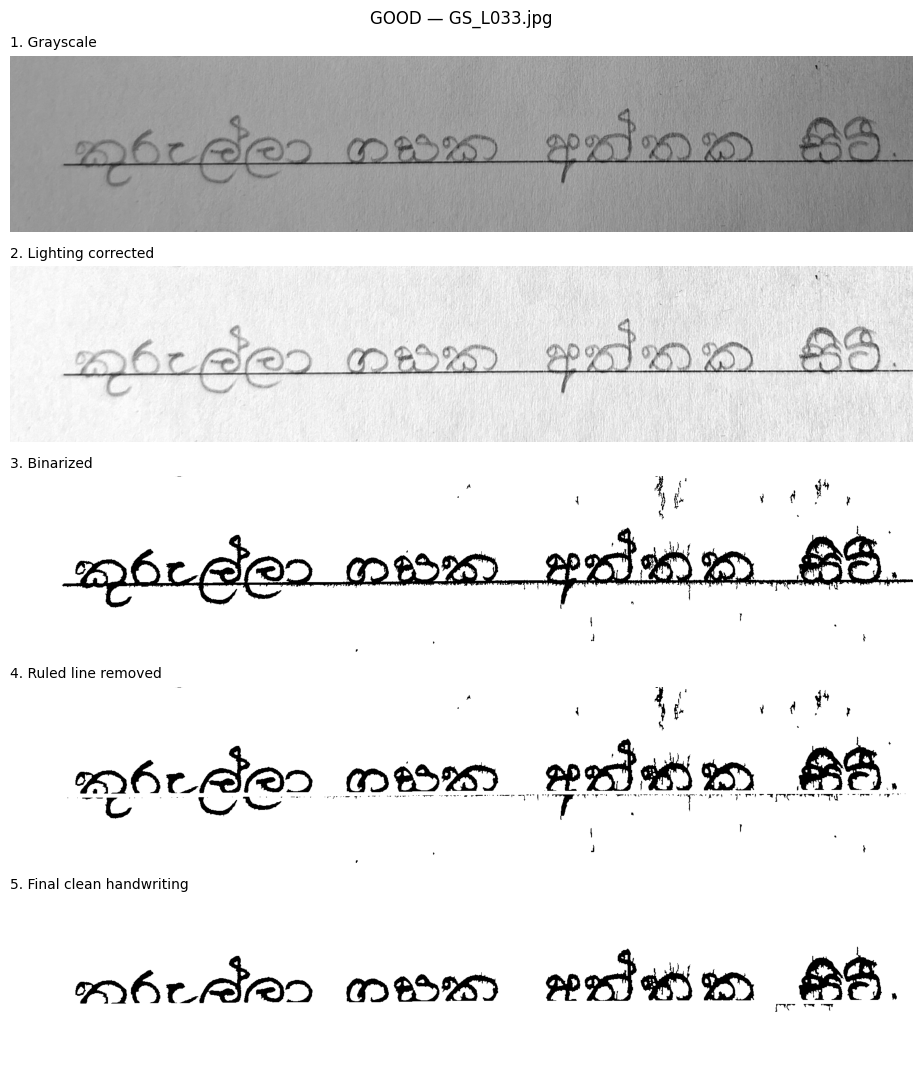

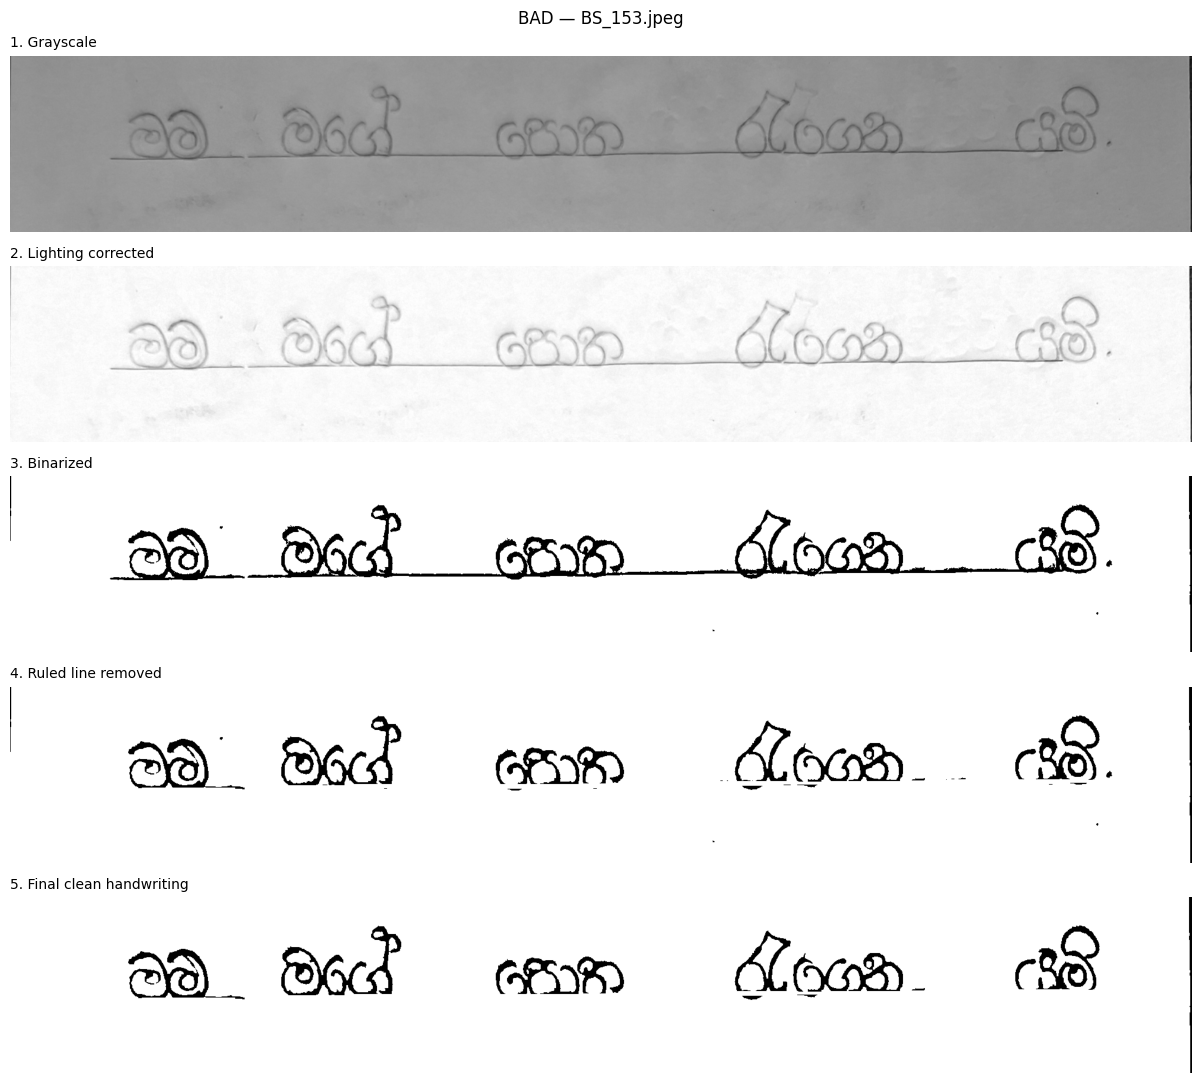

label,good (median),bad (median)
n_words,5.000000,5.000000
wg_mean,1.650498,3.580823
wg_median,1.714465,3.689588
wg_min,1.180837,2.474948
wg_max,2.077524,4.681602
wg_std,0.263774,0.777324
wg_cv,0.171715,0.228882
gap1,2.077524,4.681602
gap2,1.748874,3.959740
gap3,1.431100,3.196446


In [ ]:
# ===== 4. Features (all divided by letter height -> independent of writing size and photo resolution) =====
FEATURES = ['n_words', 'wg_mean', 'wg_median', 'wg_min', 'wg_max', 'wg_std', 'wg_cv',
            'gap1', 'gap2', 'gap3', 'ww_mean', 'ww_median', 'gap_to_word',
            'lg_mean', 'lg_max', 'wg_to_lg', 'space_ratio', 'text_len']

def make_features(m):
    wg = m['gap_w'][m['is_word']]                                  # word gaps
    lg = m['gap_w'][~m['is_word']]                                 # letter gaps (inside words)
    ww = np.array([b - a for a, b in m['words']], float) / m['h']  # word widths
    top = np.sort(m['gap_w'])[::-1][:3]
    top = np.pad(top, (0, 3 - len(top)))
    extent_px = m['words'][-1][1] - m['words'][0][0]
    gap_px = sum(b - a for a, b in m['gaps'])

    wg_mean = wg.mean() if len(wg) else 0.0
    wg_median = float(np.median(wg)) if len(wg) else 0.0
    wg_std = wg.std() if len(wg) else 0.0
    lg_mean = lg.mean() if len(lg) else 0.0
    return dict(
        n_words=len(m['words']),
        wg_mean=wg_mean, wg_median=wg_median,
        wg_min=wg.min() if len(wg) else 0.0, wg_max=wg.max() if len(wg) else 0.0,
        wg_std=wg_std, wg_cv=wg_std / wg_mean if wg_mean > 0 else 0.0,
        gap1=top[0], gap2=top[1], gap3=top[2],
        ww_mean=ww.mean(), ww_median=float(np.median(ww)),
        gap_to_word=wg_median / float(np.median(ww)),
        lg_mean=lg_mean, lg_max=lg.max() if len(lg) else 0.0,
        wg_to_lg=wg_median / max(lg_mean, 0.05),
        space_ratio=gap_px / max(extent_px, 1),
        text_len=extent_px / m['h'],
    )

# Preprocess ALL images (grayscale + cleaning), save them, extract features. Cached on Drive.
# Set REBUILD_FEATURES = True after changing any setting in section 3 (e.g. WORD_GAP_RATIO).
REBUILD_FEATURES  = False
SAVE_PREPROCESSED = True     # saves grayscale + cleaned image of every file to OUT_DIR/preprocessed/
FEAT_CSV = os.path.join(OUT_DIR, 'features.csv')

if os.path.exists(FEAT_CSV) and not REBUILD_FEATURES:
    df = pd.read_csv(FEAT_CSV)
    print(f'Loaded cached features for {len(df)} images')
else:
    rows, failed = [], []
    for r in tqdm(data.itertuples(), total=len(data), desc='Preprocessing'):
        try:
            m = measure_line(r.path)
            f = make_features(m)
        except Exception as e:
            failed.append((r.path, str(e)))
            continue
        if SAVE_PREPROCESSED:
            base = os.path.splitext(os.path.basename(r.path))[0]
            folder = os.path.join(OUT_DIR, 'preprocessed', r.split, CLASS_NAMES[r.label])
            os.makedirs(folder, exist_ok=True)
            cv2.imwrite(os.path.join(folder, base + '_gray.png'), m['gray'])
            cv2.imwrite(os.path.join(folder, base + '_clean.png'), 255 - m['mask'])
        f.update(path=r.path, label=r.label, split=r.split, letter_h_px=m['h'],
                 word_gaps=json.dumps(np.round(m['gap_w'][m['is_word']], 3).tolist()))
        rows.append(f)
    df = pd.DataFrame(rows)
    df.to_csv(FEAT_CSV, index=False)
    print(f'Preprocessed {len(df)} images, {len(failed)} failed')
    for p, e in failed:
        print('  FAILED:', os.path.basename(p), '-', e)

# show all preprocessing steps for one good and one bad example
for label in [0, 1]:
    p = df[df.label == label].path.iloc[0]
    show_steps(measure_line(p), f'{CLASS_NAMES[label].upper()} — {os.path.basename(p)}')

df.groupby('label')[FEATURES].median().T.rename(columns={0: 'good (median)', 1: 'bad (median)'})

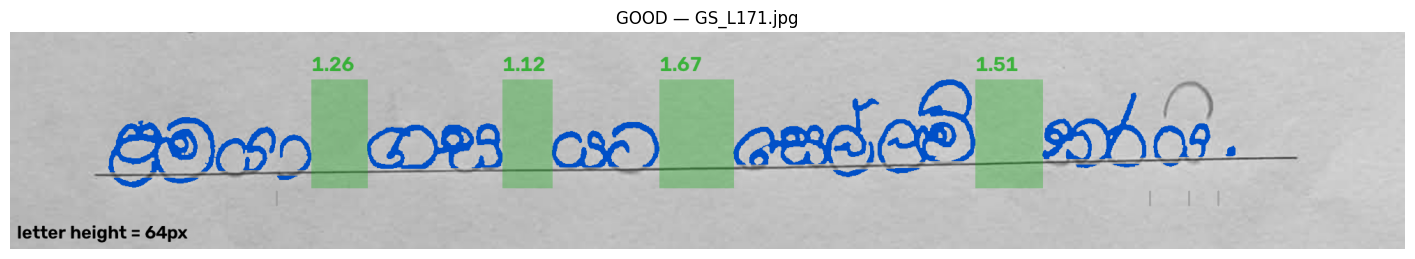

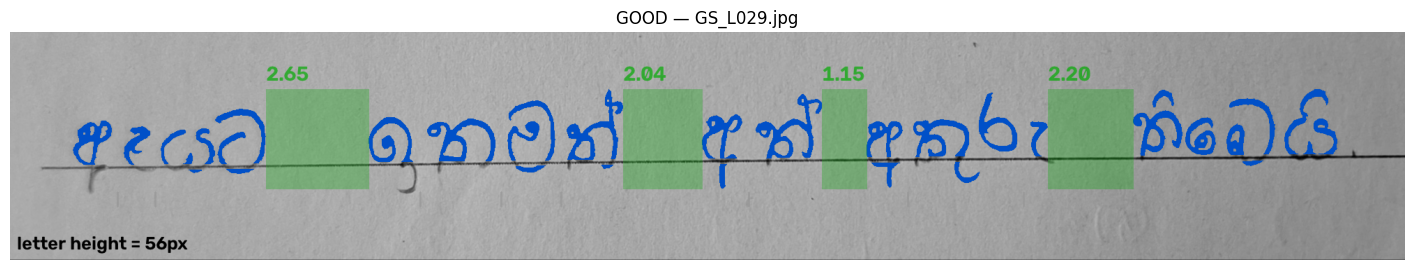

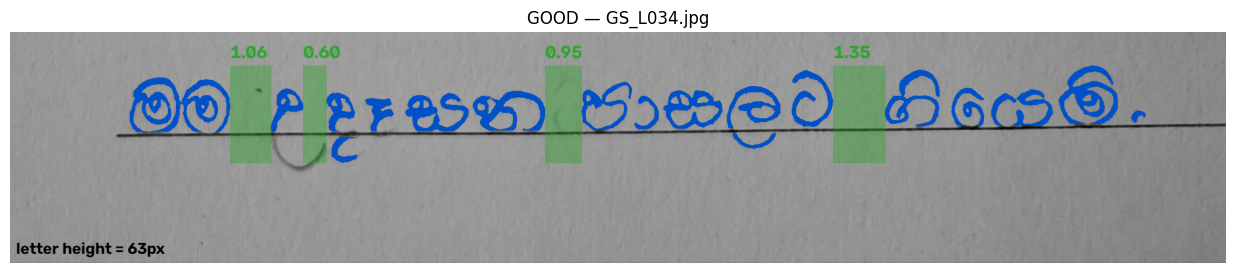

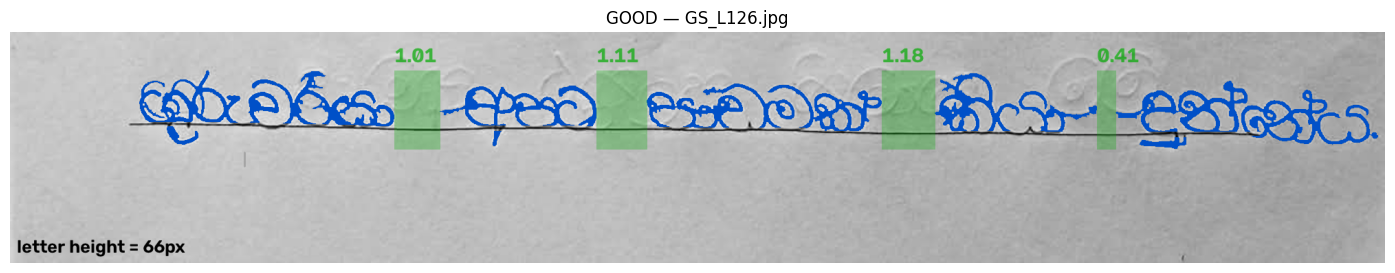

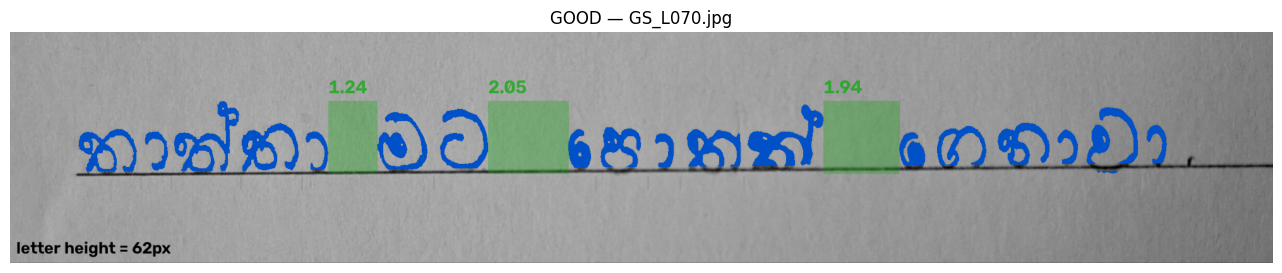

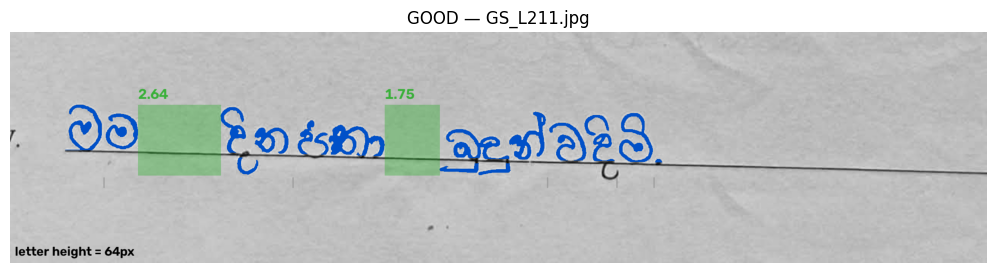

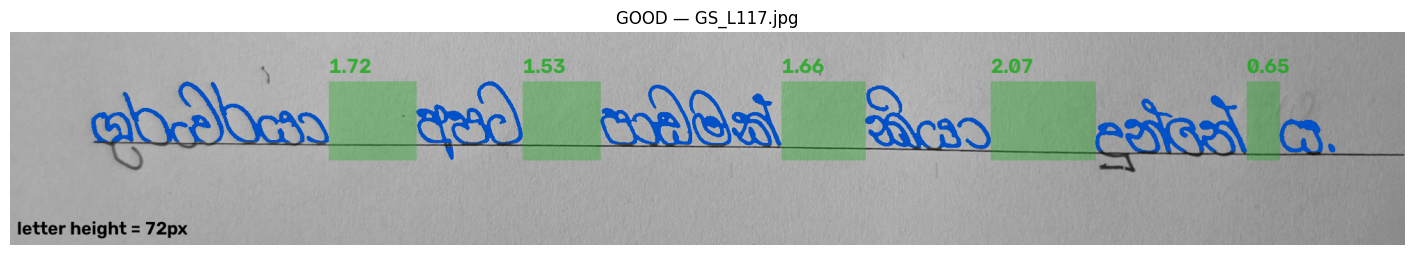

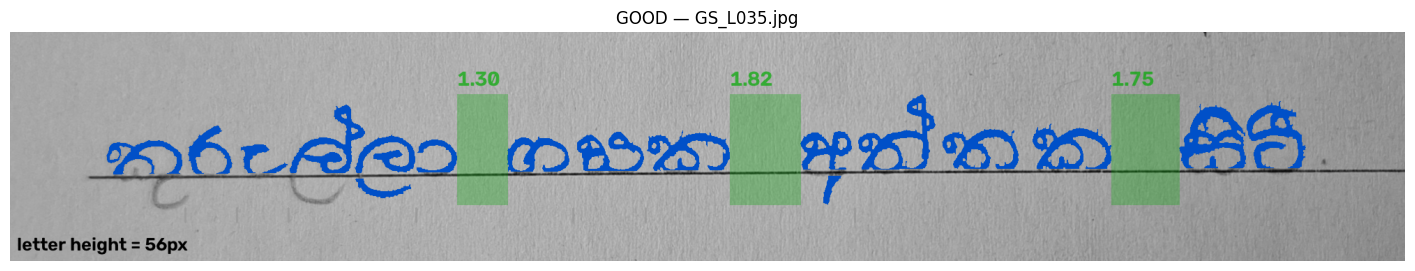

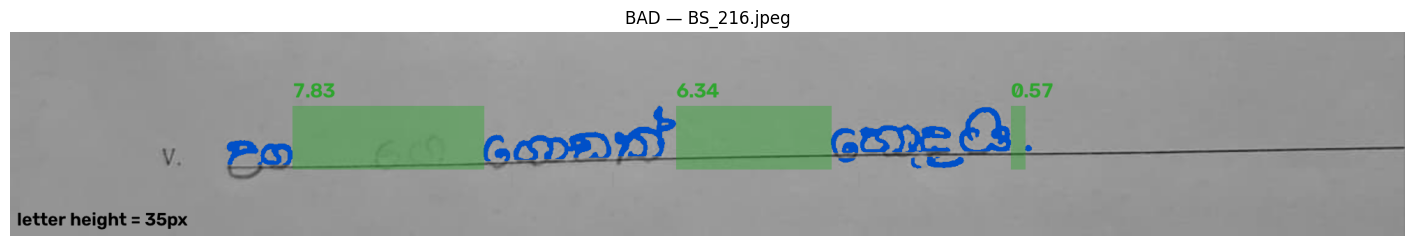

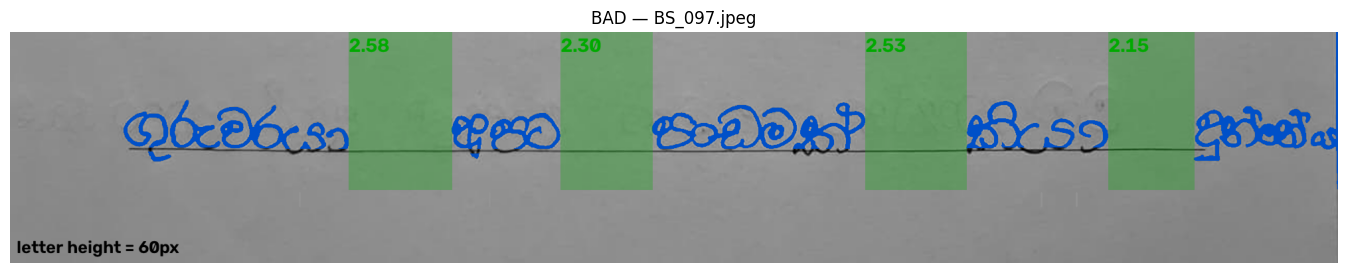

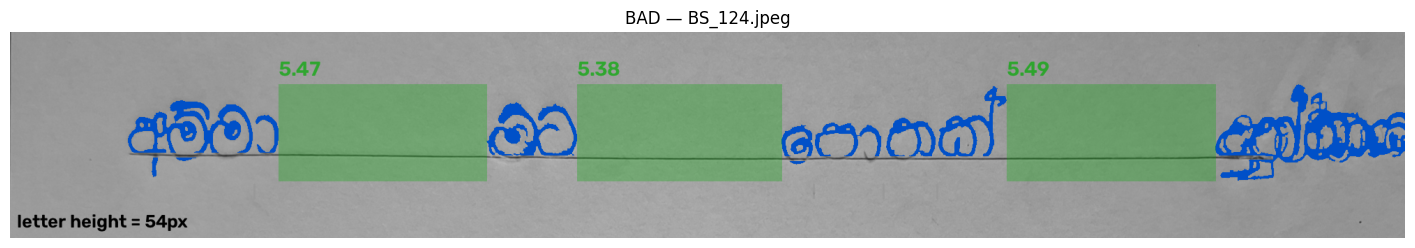

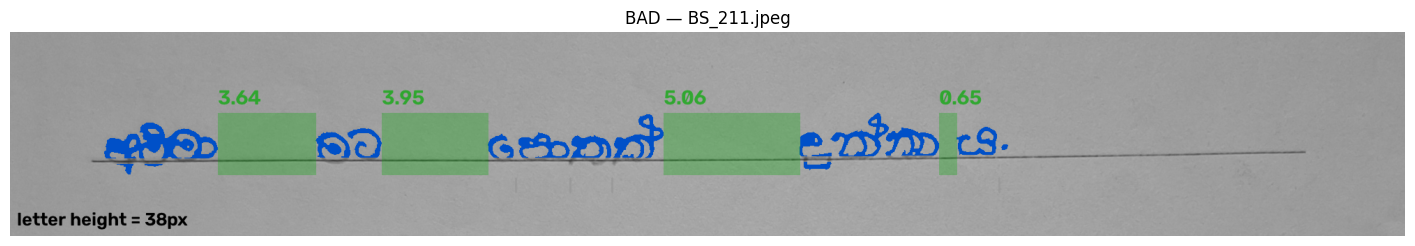

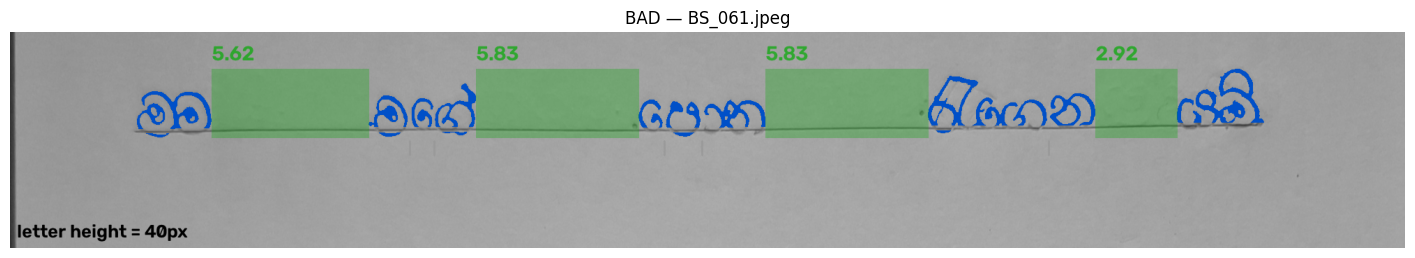

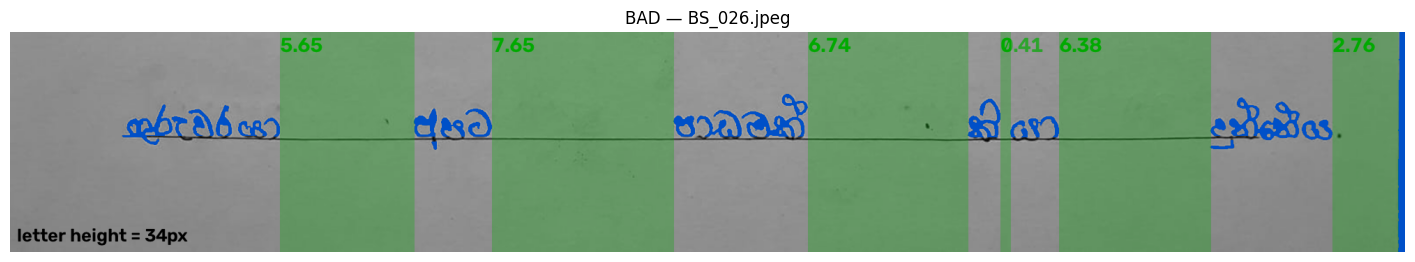

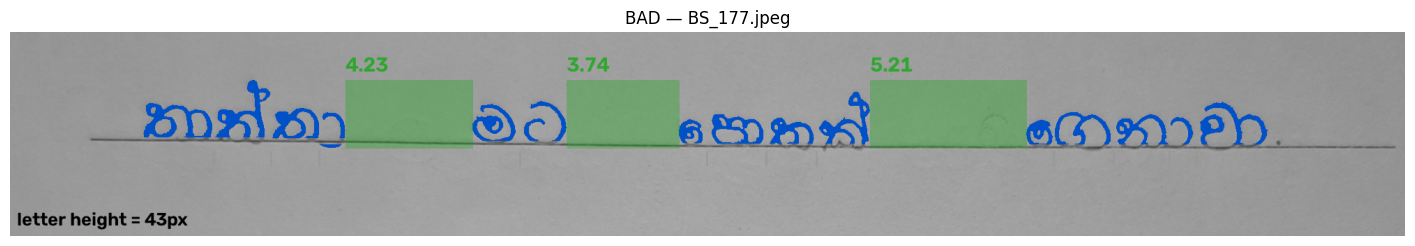

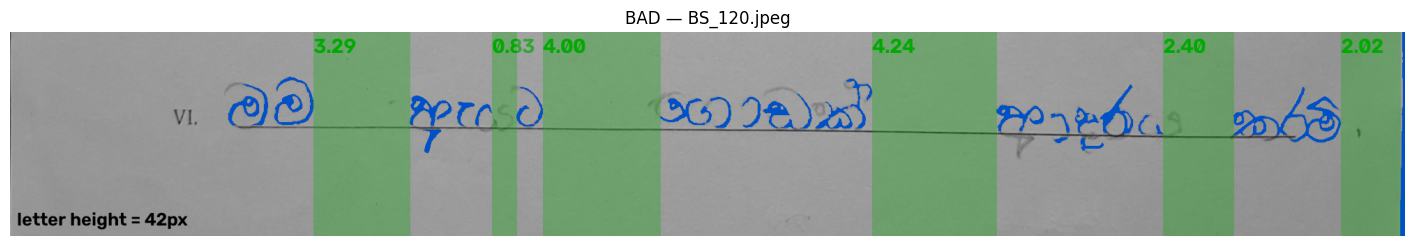

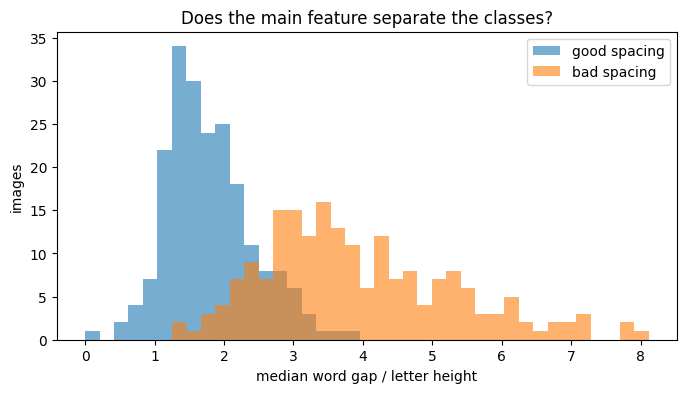

In [ ]:
# ===== 5. CHECK the gap detection before training =====
# Blue = ink kept after cleaning. Coloured boxes = word gaps (number = gap / letter height).
# Grey ticks under the line = letter gaps inside words.
# Are the word gaps found correctly? Are letter gaps NOT marked as word gaps?
# If not: change WORD_GAP_RATIO / settings in section 3, set REBUILD_FEATURES = True, rerun sections 3-5.

def draw_gaps(m, good_range=None):
    vis = cv2.cvtColor(m['gray'], cv2.COLOR_GRAY2BGR)
    vis[m['mask'] > 0] = (200, 80, 0)
    y0, y1 = m['band']
    overlay = vis.copy()
    for (a, b), g, word in zip(m['gaps'], m['gap_w'], m['is_word']):
        if not word:
            cv2.line(vis, ((a + b) // 2, y1 + 5), ((a + b) // 2, y1 + 25), (150, 150, 150), 2)
            continue
        color = (0, 170, 0)                                   # green = OK
        if good_range is not None:
            if g > good_range[1]:
                color = (0, 0, 230)                           # red = too wide
            elif g < good_range[0]:
                color = (0, 140, 255)                         # orange = too narrow
        cv2.rectangle(overlay, (a, y0), (b, y1), color, -1)
        cv2.putText(vis, f'{g:.2f}', (a, max(y0 - 12, 30)), cv2.FONT_HERSHEY_SIMPLEX, 1.0, color, 2)
    vis = cv2.addWeighted(overlay, 0.3, vis, 0.7, 0)
    cv2.putText(vis, f'letter height = {m["h"]:.0f}px', (10, vis.shape[0] - 15),
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 0), 2)
    return vis

def show(img_bgr, title=''):
    plt.figure(figsize=(18, 3))
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

random.seed(SEED)
for label in [0, 1]:
    paths = df[(df.label == label) & (df.split == 'train')].path.tolist()
    for p in random.sample(paths, min(8, len(paths))):
        vis = draw_gaps(measure_line(p))
        cv2.imwrite(os.path.join(OUT_DIR, 'debug', f'{CLASS_NAMES[label]}_{os.path.basename(p)}'), vis)
        show(vis, f'{CLASS_NAMES[label].upper()} — {os.path.basename(p)}')

plt.figure(figsize=(8, 4))
bins = np.linspace(0, df.wg_median.quantile(0.99), 40)
for label in [0, 1]:
    plt.hist(df[df.label == label].wg_median, bins, alpha=0.6, label=f'{CLASS_NAMES[label]} spacing')
plt.xlabel('median word gap / letter height')
plt.ylabel('images')
plt.title('Does the main feature separate the classes?')
plt.legend()
plt.show()

train=284  val=62  test=62
Best settings: max_depth = 5, min_samples_leaf = 2, max_features = sqrt
Cross-validation F1 on train: 0.912 ± 0.036


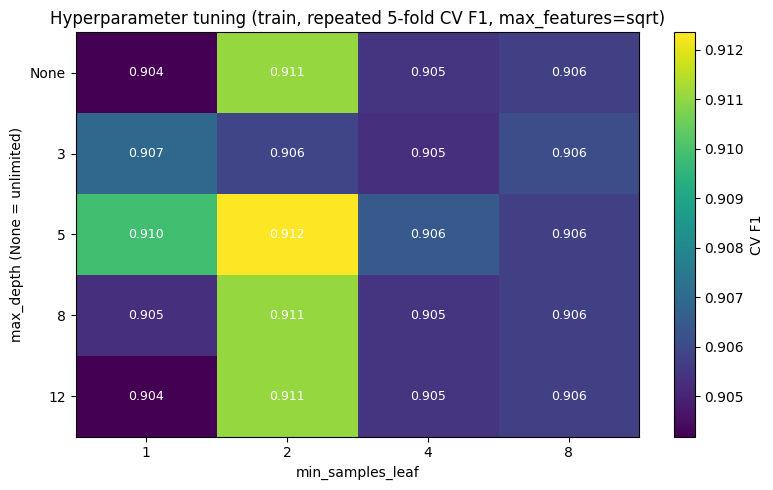


TRAIN vs VALIDATION:


,Train,Validation
Accuracy,0.9683,0.8871
Balanced accuracy,0.9684,0.8871
Precision (bad),0.9645,0.8750
Recall / Sensitivity,0.9714,0.9032
Specificity,0.9653,0.8710
F1 (bad),0.9680,0.8889
F1 macro,0.9683,0.8871
ROC-AUC,0.9990,0.9688
PR-AUC (avg precision),0.9990,0.9745
MCC,0.9366,0.7746


In [ ]:
# ===== 6. Random Forest: tune on TRAIN (cross-validation), check on VALIDATION =====
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef, cohen_kappa_score,
                             log_loss, brier_score_loss, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay

MODEL_NAME = 'Random Forest'

tr, va, te = (df[df.split == s] for s in ['train', 'val', 'test'])
X_train, y_train = tr[FEATURES], tr.label.values
X_val,   y_val   = va[FEATURES], va.label.values
X_test,  y_test  = te[FEATURES], te.label.values
print(f'train={len(tr)}  val={len(va)}  test={len(te)}')

def all_metrics(y_true, prob, thr=0.5):
    """Every evaluation metric for binary classification (positive class = bad spacing)."""
    pred = (prob > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        'Accuracy':               accuracy_score(y_true, pred),
        'Balanced accuracy':      balanced_accuracy_score(y_true, pred),
        'Precision (bad)':        precision_score(y_true, pred, zero_division=0),
        'Recall / Sensitivity':   recall_score(y_true, pred, zero_division=0),
        'Specificity':            tn / (tn + fp) if tn + fp else 0.0,
        'F1 (bad)':               f1_score(y_true, pred, zero_division=0),
        'F1 macro':               f1_score(y_true, pred, average='macro', zero_division=0),
        'ROC-AUC':                roc_auc_score(y_true, prob),
        'PR-AUC (avg precision)': average_precision_score(y_true, prob),
        'MCC':                    matthews_corrcoef(y_true, pred),
        "Cohen's kappa":          cohen_kappa_score(y_true, pred),
        'Log loss':               log_loss(y_true, np.clip(prob, 1e-6, 1 - 1e-6), labels=[0, 1]),
        'Brier score':            brier_score_loss(y_true, prob),
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
    }

# Random Forest does not need feature scaling. oob_score=True gives an extra "out-of-bag" accuracy estimate.
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)

# Tune tree depth, leaf size and features-per-split with repeated 5-fold CV on the TRAIN set
DEPTH_VALUES = [None, 3, 5, 8, 12]
LEAF_VALUES  = [1, 2, 4, 8]
param_grid = {'max_depth': DEPTH_VALUES, 'min_samples_leaf': LEAF_VALUES, 'max_features': ['sqrt', 0.5]}
search = GridSearchCV(rf, param_grid, scoring='f1', n_jobs=-1,
                      cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED))
search.fit(X_train, y_train)
best_params = search.best_params_
best_i = search.best_index_
print(f'Best settings: max_depth = {best_params["max_depth"]}, min_samples_leaf = {best_params["min_samples_leaf"]}, '
      f'max_features = {best_params["max_features"]}')
print(f'Cross-validation F1 on train: {search.cv_results_["mean_test_score"][best_i]:.3f} '
      f'± {search.cv_results_["std_test_score"][best_i]:.3f}')

# Heatmap: CV F1 for every (max_depth, min_samples_leaf), using the best max_features
cvres = pd.DataFrame(search.cv_results_)
sub = cvres[cvres.param_max_features.astype(str) == str(best_params['max_features'])]
heat = sub.pivot_table(index=sub.param_max_depth.astype(str), columns=sub.param_min_samples_leaf.astype(int),
                       values='mean_test_score').reindex([str(d) for d in DEPTH_VALUES])
plt.figure(figsize=(8, 5))
plt.imshow(heat.values, cmap='viridis', aspect='auto')
plt.colorbar(label='CV F1')
plt.xticks(range(len(heat.columns)), heat.columns)
plt.yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        plt.text(j, i, f'{heat.values[i, j]:.3f}', ha='center', va='center', color='white', fontsize=9)
plt.xlabel('min_samples_leaf')
plt.ylabel('max_depth (None = unlimited)')
plt.title(f'Hyperparameter tuning (train, repeated 5-fold CV F1, max_features={best_params["max_features"]})')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_tuning_heatmap.png'), dpi=150)
plt.show()
cvres[['param_max_depth', 'param_min_samples_leaf', 'param_max_features', 'mean_test_score', 'std_test_score',
       'rank_test_score']].sort_values('rank_test_score').to_csv(os.path.join(OUT_DIR, 'rf_tuning_results.csv'), index=False)

# Model trained on TRAIN only -> check on VALIDATION
model_tr = search.best_estimator_
m_train = all_metrics(y_train, model_tr.predict_proba(X_train)[:, 1])
m_val   = all_metrics(y_val,   model_tr.predict_proba(X_val)[:, 1])
trval_table = pd.DataFrame({'Train': m_train, 'Validation': m_val}).astype(float).round(4)
trval_table.to_csv(os.path.join(OUT_DIR, 'rf_train_vs_validation.csv'))
print('\nTRAIN vs VALIDATION:')
display(trval_table)

  TEST ACCURACY (Random Forest): 87.10%   (95% CI 79.0% – 95.2%)


,Metric,Value,95% CI
0,Accuracy,0.8710,0.790 – 0.952
1,Balanced accuracy,0.8710,0.785 – 0.952
2,Precision (bad),0.8710,0.750 – 0.974
3,Recall / Sensitivity,0.8710,0.741 – 0.971
4,Specificity,0.8710,0.739 – 0.972
5,F1 (bad),0.8710,0.775 – 0.954
6,F1 macro,0.8710,0.786 – 0.951
7,ROC-AUC,0.9448,0.877 – 0.989
8,PR-AUC (avg precision),0.9359,0.843 – 0.991
9,MCC,0.7419,0.572 – 0.903



Classification report (test):
              precision    recall  f1-score   support

        good     0.8710    0.8710    0.8710        31
         bad     0.8710    0.8710    0.8710        31

    accuracy                         0.8710        62
   macro avg     0.8710    0.8710    0.8710        62
weighted avg     0.8710    0.8710    0.8710        62



,Split,Accuracy,F1 (bad)
0,Train,0.9683,0.9680
1,Validation,0.8871,0.8889
2,Test,0.8710,0.8710


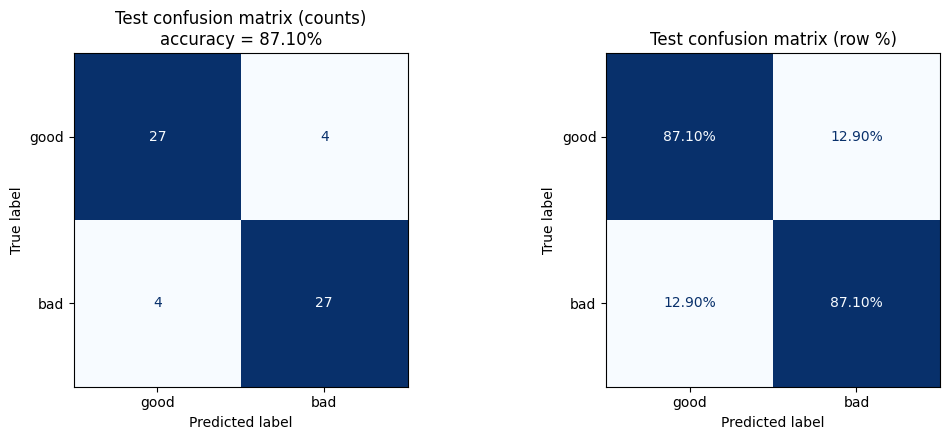

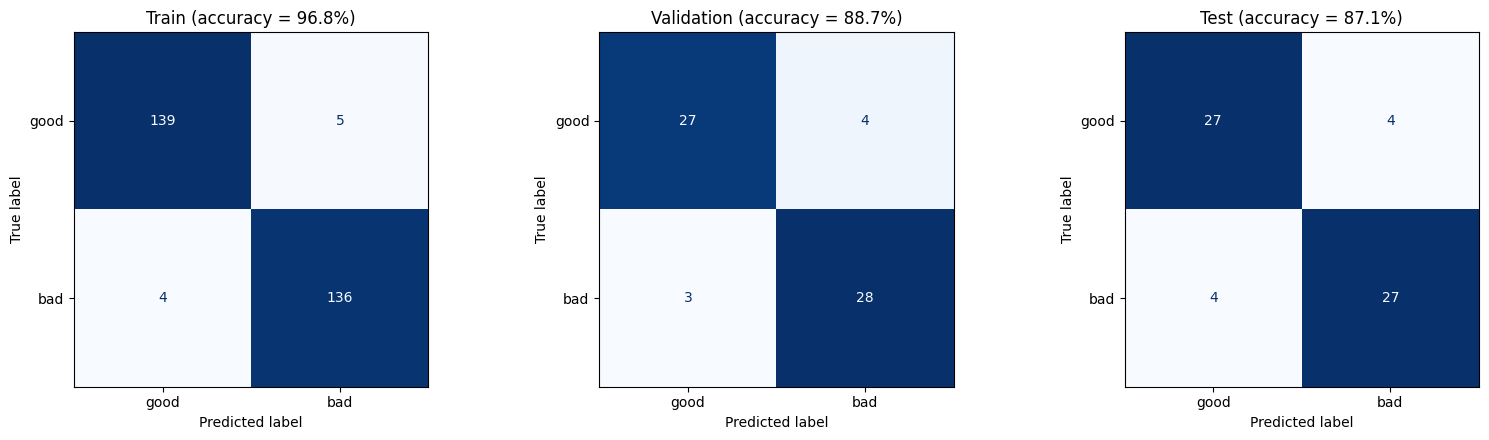

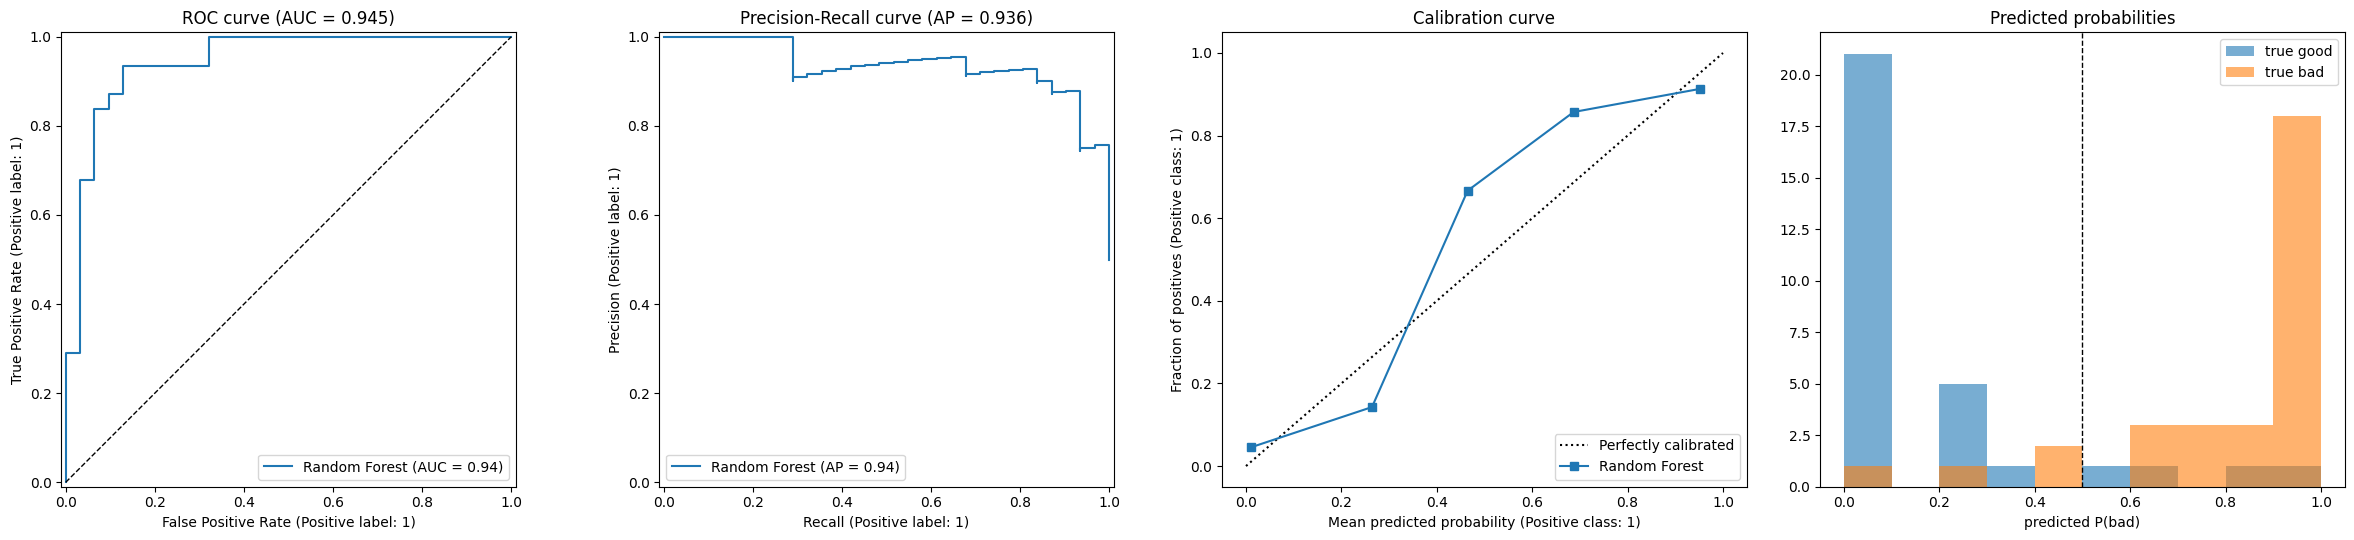

Out-of-bag accuracy (train + validation): 89.60%


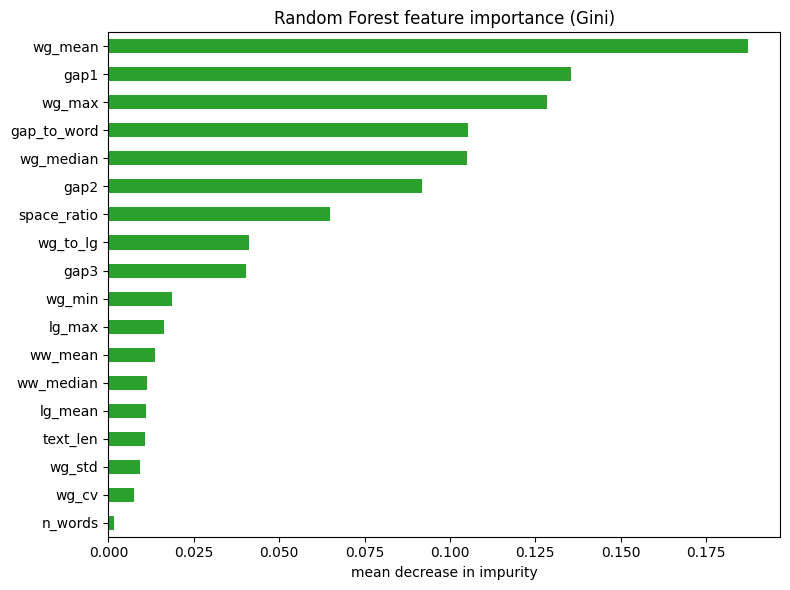

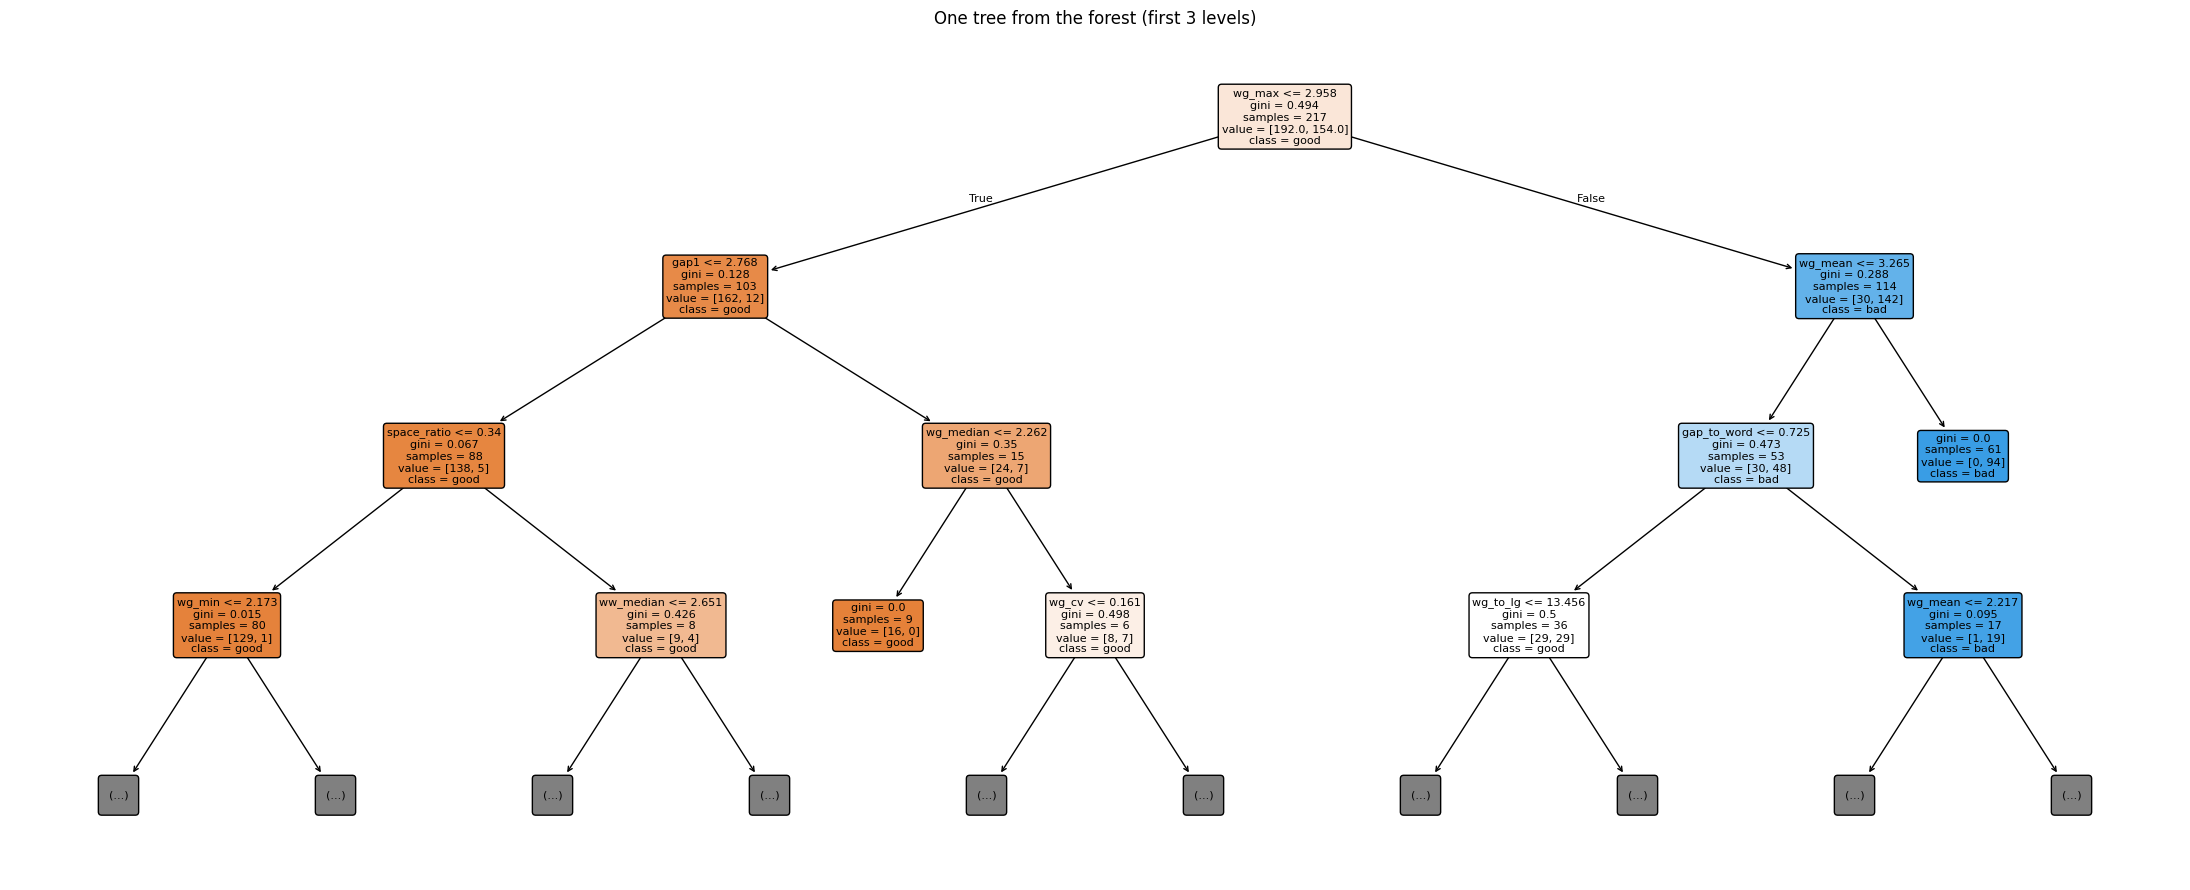

8 misclassified test images (saved to rf_test_misclassified.csv)


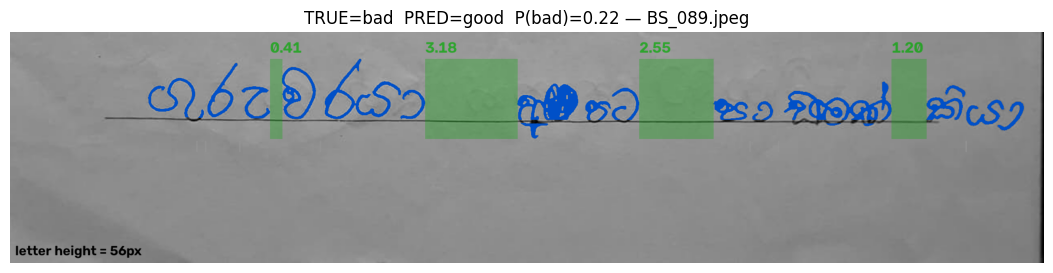

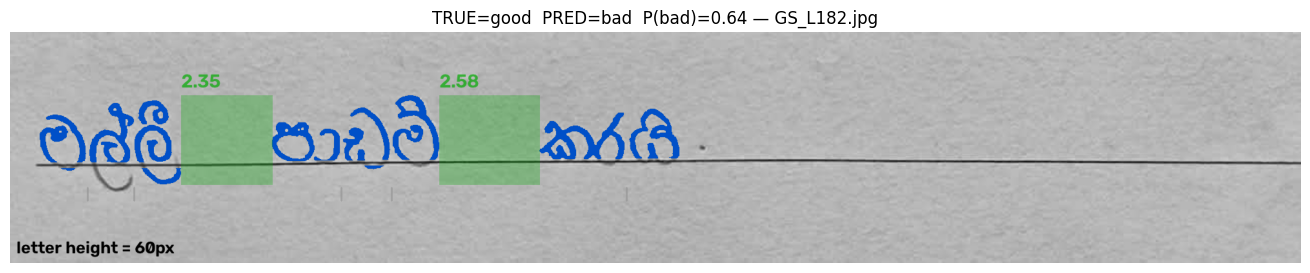

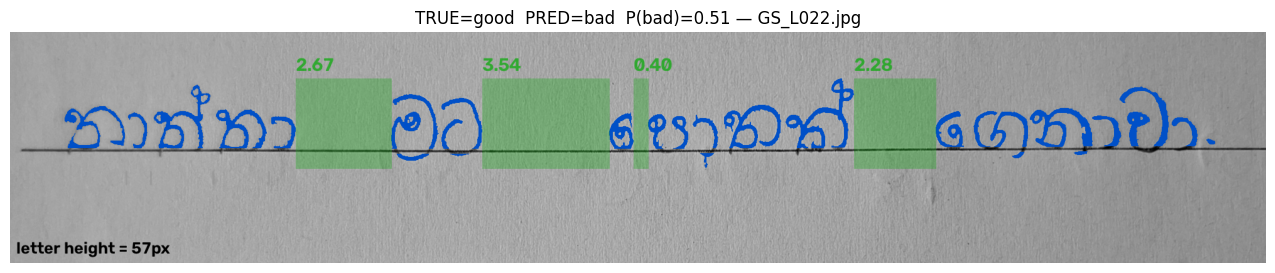

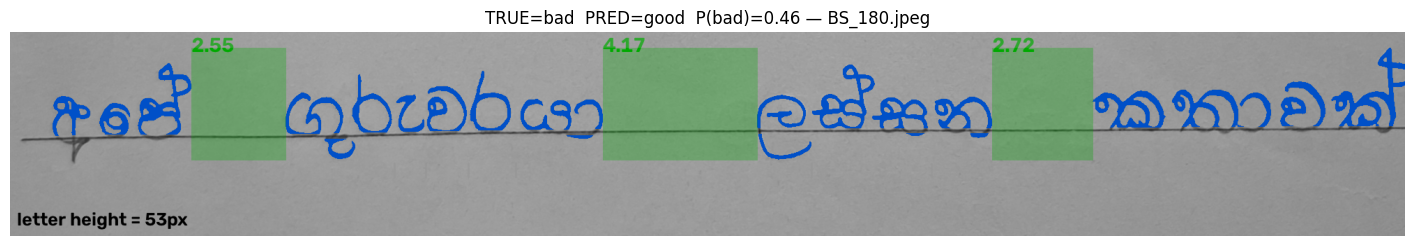

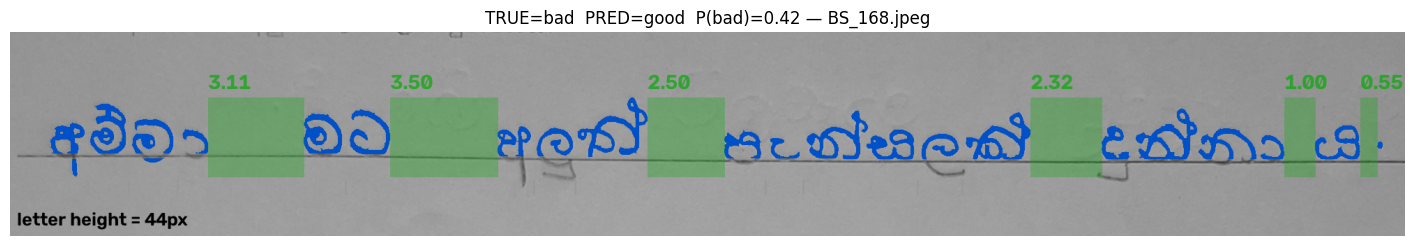

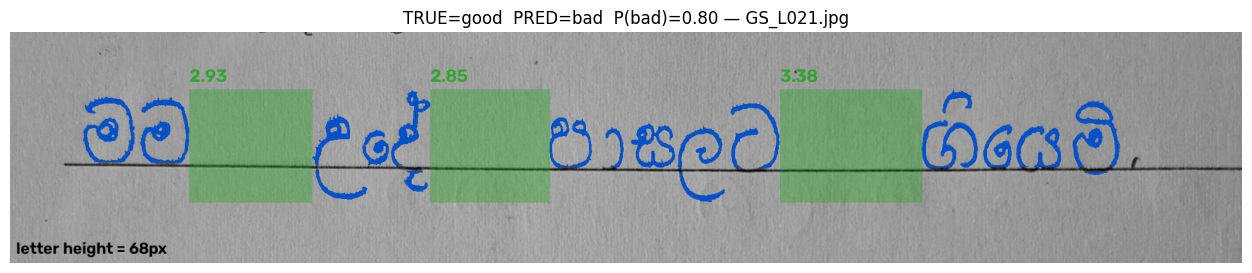

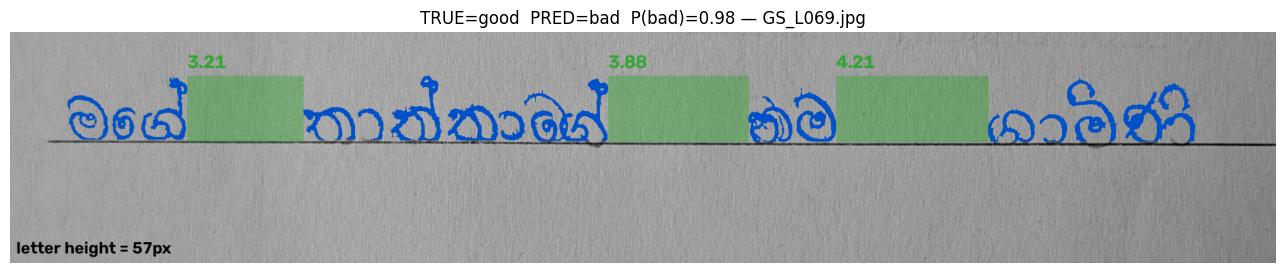

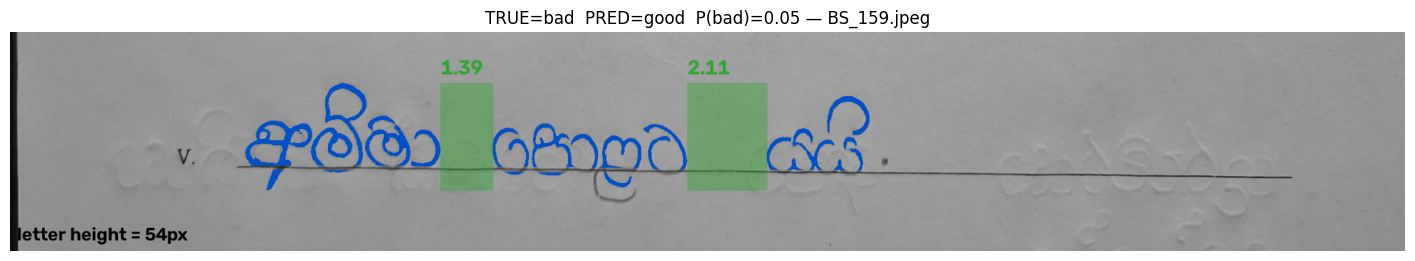

In [ ]:
# ===== 7. FINAL EVALUATION ON THE TEST SET =====
# The tuned model is retrained on train + validation, then evaluated ONCE on the unseen test set.
X_trval = pd.concat([X_train, X_val])
y_trval = np.concatenate([y_train, y_val])
final_model = clone(model_tr).fit(X_trval, y_trval)

prob_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (prob_test > 0.5).astype(int)
m = all_metrics(y_test, prob_test)

# 95% confidence intervals with bootstrap (the test set is small, so the CI shows how certain each number is)
def bootstrap_ci(y_true, prob, n_boot=1000):
    rng = np.random.default_rng(SEED)
    keys = [k for k in m if k not in ('TP', 'TN', 'FP', 'FN')]
    samples = {k: [] for k in keys}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        mb = all_metrics(y_true[idx], prob[idx])
        for k in keys:
            samples[k].append(mb[k])
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in samples.items()}

ci = bootstrap_ci(y_test, prob_test)

print('=' * 60)
print(f'  TEST ACCURACY ({MODEL_NAME}): {m["Accuracy"] * 100:.2f}%'
      f'   (95% CI {ci["Accuracy"][0] * 100:.1f}% – {ci["Accuracy"][1] * 100:.1f}%)')
print('=' * 60)
test_table = pd.DataFrame({
    'Metric': list(m),
    'Value': [round(float(v), 4) for v in m.values()],
    '95% CI': [f'{ci[k][0]:.3f} – {ci[k][1]:.3f}' if k in ci else '' for k in m],
})
test_table.to_csv(os.path.join(OUT_DIR, 'test_metrics_rf.csv'), index=False)
display(test_table)

report = classification_report(y_test, pred_test, target_names=CLASS_NAMES, digits=4)
print('\nClassification report (test):')
print(report)
with open(os.path.join(OUT_DIR, 'rf_classification_report.txt'), 'w') as fh:
    fh.write(report)

# Accuracy per split (overfitting check)
split_table = pd.DataFrame({'Split': ['Train', 'Validation', 'Test'],
                            'Accuracy': [m_train['Accuracy'], m_val['Accuracy'], m['Accuracy']],
                            'F1 (bad)': [m_train['F1 (bad)'], m_val['F1 (bad)'], m['F1 (bad)']]}).round(4)
split_table.to_csv(os.path.join(OUT_DIR, 'rf_accuracy_per_split.csv'), index=False)
display(split_table)

# ---------- Confusion matrices ----------
# Test set: counts and normalised (row %)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=CLASS_NAMES, cmap='Blues',
                                        ax=axes[0], colorbar=False)
axes[0].set_title(f'Test confusion matrix (counts)\naccuracy = {m["Accuracy"] * 100:.2f}%')
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=CLASS_NAMES, cmap='Blues',
                                        normalize='true', values_format='.2%', ax=axes[1], colorbar=False)
axes[1].set_title('Test confusion matrix (row %)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_confusion_matrix_test.png'), dpi=150)
plt.show()

# Train / validation / test side by side (train & validation use the model trained on train only)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, yt, yp) in zip(axes, [('Train', y_train, model_tr.predict(X_train)),
                                     ('Validation', y_val, model_tr.predict(X_val)),
                                     ('Test', y_test, pred_test)]):
    ConfusionMatrixDisplay.from_predictions(yt, yp, display_labels=CLASS_NAMES, cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'{name} (accuracy = {accuracy_score(yt, yp) * 100:.1f}%)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_confusion_matrix_all_splits.png'), dpi=150)
plt.show()

pd.DataFrame(confusion_matrix(y_test, pred_test, labels=[0, 1]),
             index=[f'true {c}' for c in CLASS_NAMES], columns=[f'pred {c}' for c in CLASS_NAMES]) \
    .to_csv(os.path.join(OUT_DIR, 'rf_confusion_matrix_test.csv'))

# ROC, Precision-Recall, calibration and predicted-probability distribution
fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
RocCurveDisplay.from_predictions(y_test, prob_test, name=MODEL_NAME, ax=axes[0])
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title(f'ROC curve (AUC = {m["ROC-AUC"]:.3f})')
PrecisionRecallDisplay.from_predictions(y_test, prob_test, name=MODEL_NAME, ax=axes[1])
axes[1].set_title(f'Precision-Recall curve (AP = {m["PR-AUC (avg precision)"]:.3f})')
CalibrationDisplay.from_predictions(y_test, prob_test, n_bins=5, name=MODEL_NAME, ax=axes[2])
axes[2].set_title('Calibration curve')
for label in [0, 1]:
    axes[3].hist(prob_test[y_test == label], bins=np.linspace(0, 1, 11), alpha=0.6, label=f'true {CLASS_NAMES[label]}')
axes[3].axvline(0.5, color='k', ls='--', lw=1)
axes[3].set_xlabel('predicted P(bad)')
axes[3].set_title('Predicted probabilities')
axes[3].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_test_curves.png'), dpi=150)
plt.show()

# Random-Forest-specific: out-of-bag accuracy, built-in (Gini) feature importance and one example tree
from sklearn.tree import plot_tree
print(f'Out-of-bag accuracy (train + validation): {final_model.oob_score_ * 100:.2f}%')

gini = pd.Series(final_model.feature_importances_, index=FEATURES).sort_values()
gini.to_frame('gini_importance').sort_values('gini_importance', ascending=False) \
    .to_csv(os.path.join(OUT_DIR, 'rf_gini_importance.csv'))
plt.figure(figsize=(8, 6))
gini.plot.barh(color='tab:green')
plt.xlabel('mean decrease in impurity')
plt.title('Random Forest feature importance (Gini)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_gini_importance.png'), dpi=150)
plt.show()

plt.figure(figsize=(22, 9))
plot_tree(final_model.estimators_[0], feature_names=FEATURES, class_names=CLASS_NAMES, filled=True,
          rounded=True, max_depth=3, fontsize=8)
plt.title('One tree from the forest (first 3 levels)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_example_tree.png'), dpi=150)
plt.show()

# Misclassified test images
wrong = te.assign(prob_bad=prob_test, pred=pred_test)
wrong = wrong[wrong.pred != wrong.label]
wrong[['path', 'label', 'prob_bad', 'wg_median', 'n_words']].to_csv(os.path.join(OUT_DIR, 'rf_test_misclassified.csv'), index=False)
print(f'{len(wrong)} misclassified test images (saved to rf_test_misclassified.csv)')
os.makedirs(os.path.join(OUT_DIR, 'misclassified'), exist_ok=True)
for _, r in wrong.iterrows():
    vis = draw_gaps(measure_line(r.path))
    cv2.imwrite(os.path.join(OUT_DIR, 'misclassified', os.path.basename(r.path)), vis)
    show(vis, f'TRUE={CLASS_NAMES[r.label]}  PRED={CLASS_NAMES[r.pred]}  P(bad)={r.prob_bad:.2f} — {os.path.basename(r.path)}')

A. Repeated stratified 10-fold cross-validation (10 repeats, all images):
   CV accuracy = 90.73% ± 4.30%


,Metric,CV mean,CV std,CV min,CV max,Train mean
0,Accuracy,0.9073,0.0430,0.7561,1.0000,0.9623
1,Balanced accuracy,0.9074,0.0429,0.7536,1.0000,0.9624
2,Precision (bad),0.8952,0.0576,0.7308,1.0000,0.9541
3,Recall / Sensitivity,0.9252,0.0567,0.6500,1.0000,0.9706
4,Specificity,0.8897,0.0672,0.6667,1.0000,0.9542
5,F1 (bad),0.9082,0.0430,0.7222,1.0000,0.9623
6,F1 macro,0.9070,0.0434,0.7524,1.0000,0.9623
7,ROC-AUC,0.9682,0.0234,0.8714,1.0000,0.9967
8,PR-AUC (avg precision),0.9672,0.0266,0.8621,1.0000,0.9967
9,MCC,0.8183,0.0840,0.5197,1.0000,0.9248


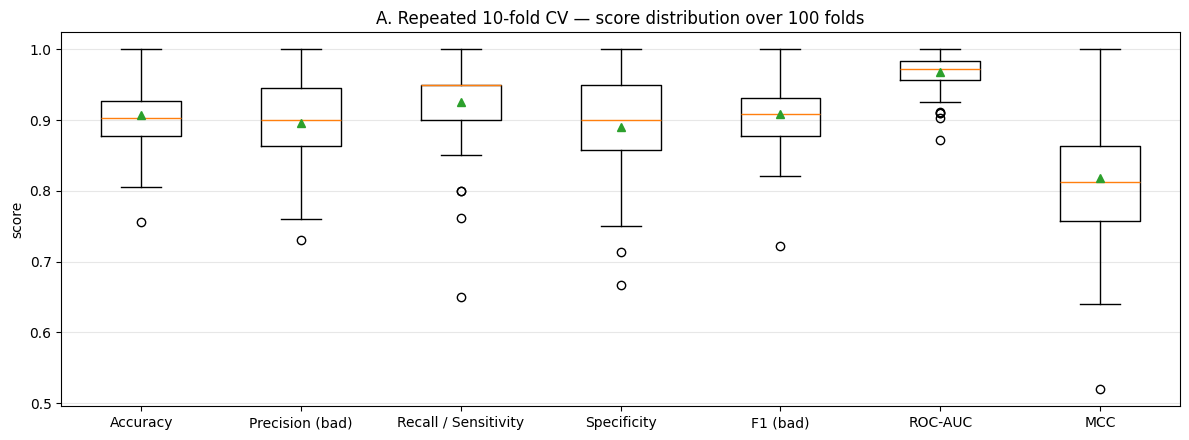

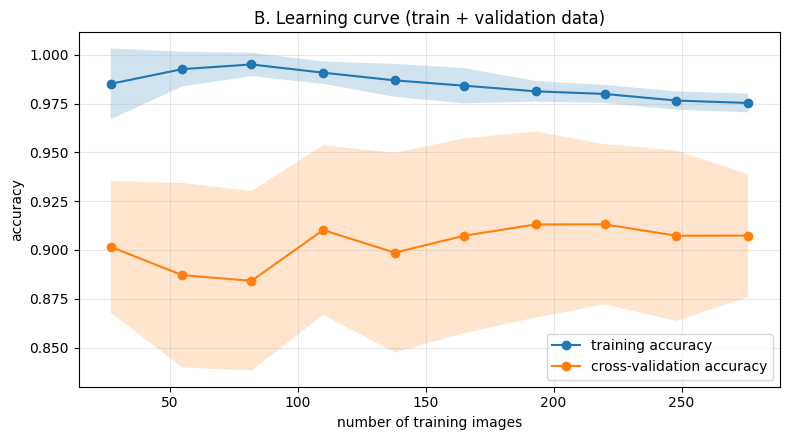

B. Gap between training and CV accuracy at full size: 6.8 points (small gap = little overfitting; a still-rising CV curve = more data would help)

C. Youden threshold (chosen on validation) = 0.748


,Threshold 0.5,Threshold 0.75
Accuracy,0.8710,0.8387
Balanced accuracy,0.8710,0.8387
Precision (bad),0.8710,0.9200
Recall / Sensitivity,0.8710,0.7419
Specificity,0.8710,0.9355
F1 (bad),0.8710,0.8214
F1 macro,0.8710,0.8372
ROC-AUC,0.9448,0.9448
PR-AUC (avg precision),0.9359,0.9359
MCC,0.7419,0.6905


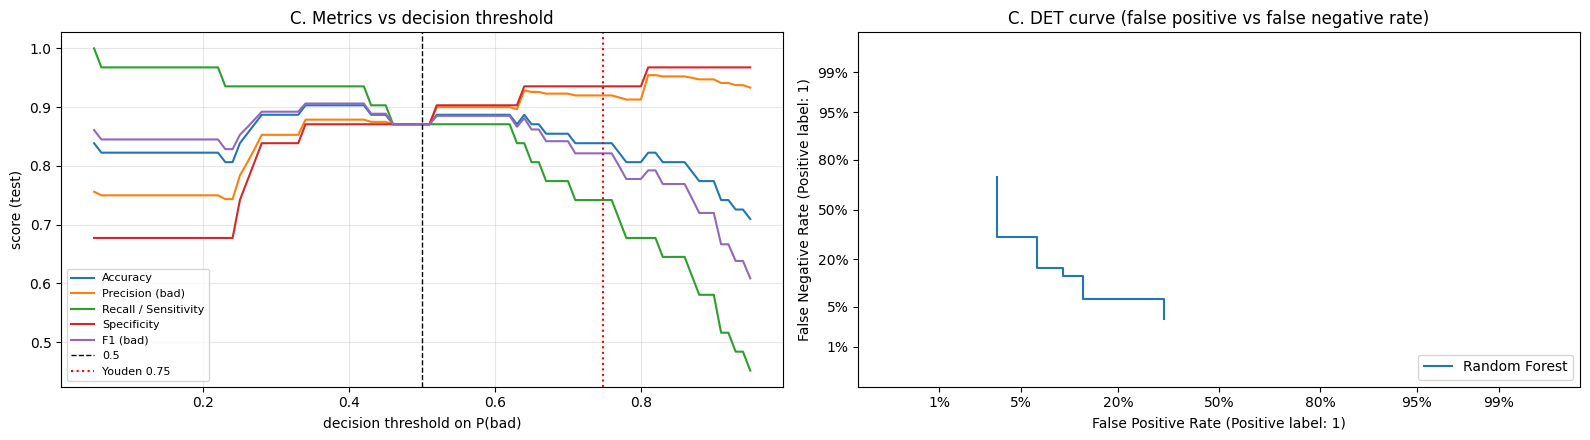

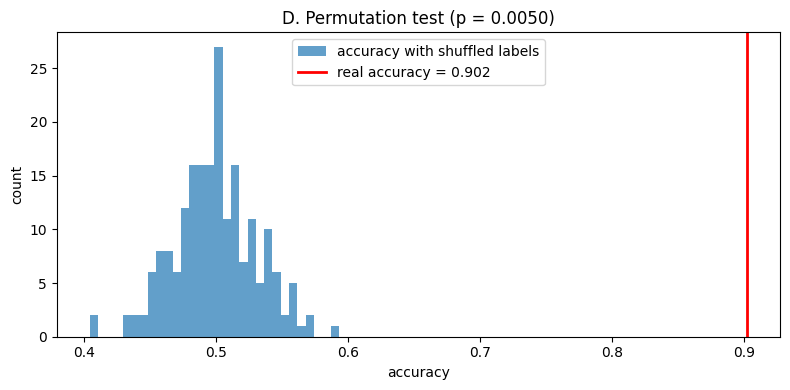

D. Permutation test: accuracy 0.902 vs chance 0.500, p-value = 0.0050  -> significantly better than chance


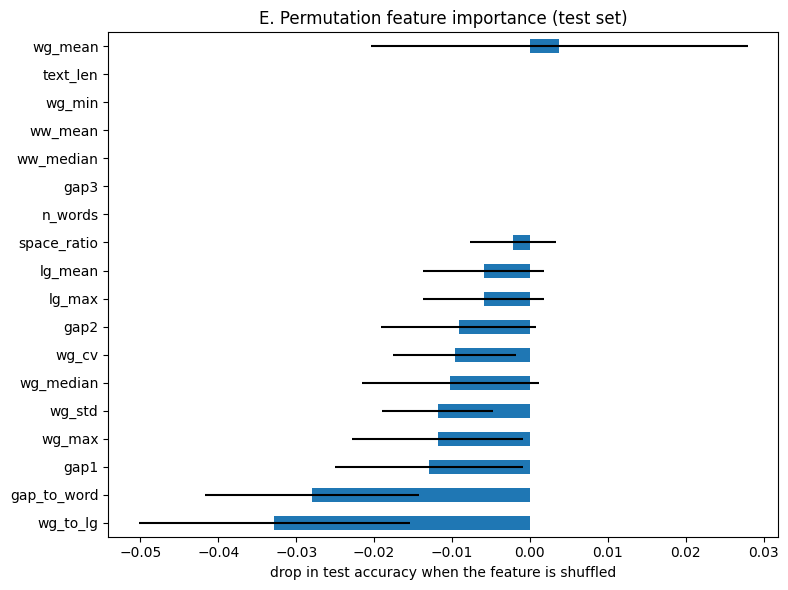

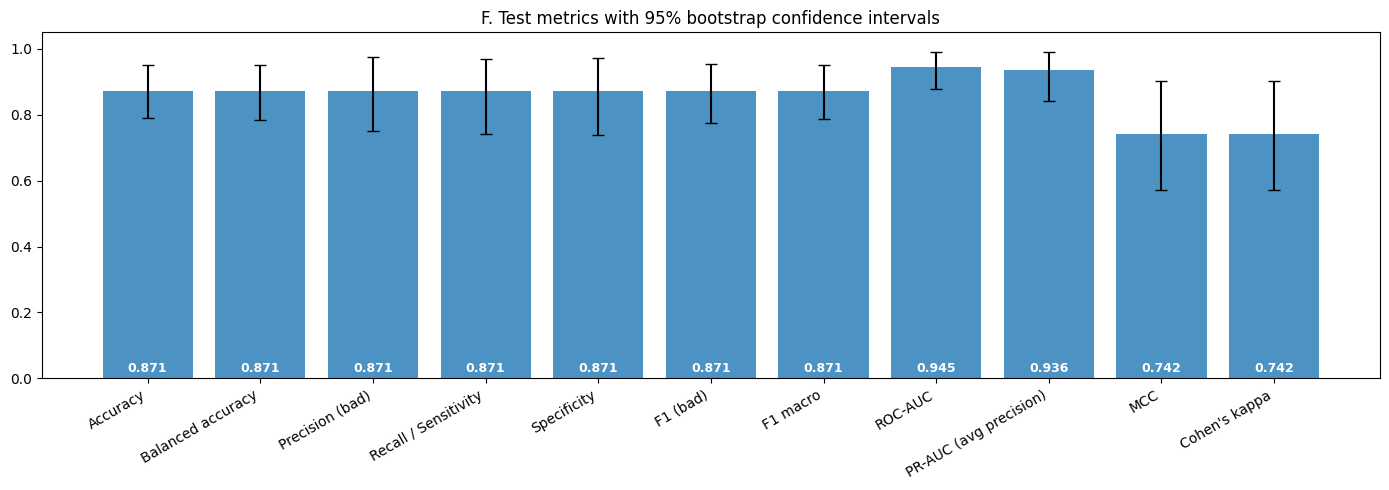


EVALUATION SUMMARY


,Evaluation,Result
0,Test accuracy (threshold 0.5),87.10% (95% CI 79.0–95.2%)
1,Test F1 (bad),0.871
2,Test ROC-AUC,0.945
3,Repeated 10-fold CV accuracy,90.73% ± 4.30%
4,Repeated 10-fold CV F1,0.908
5,Test accuracy (Youden threshold 0.75),83.87%
6,Permutation test p-value,0.0050
7,Train / Val / Test accuracy,0.968 / 0.887 / 0.871


In [ ]:
# ===== 7b. ADDITIONAL EVALUATION METHODS =====
#   A. Repeated stratified 10-fold cross-validation (all metrics, mean ± std)
#   B. Learning curve (does more data help? over/underfitting?)
#   C. Decision-threshold analysis (Youden's J threshold chosen on validation, applied to test)
#   D. Permutation test (is the model significantly better than chance?)
#   E. Permutation feature importance on the test set
#   F. Test metrics chart with 95% confidence intervals
from sklearn.model_selection import cross_validate, learning_curve, permutation_test_score, StratifiedKFold
from sklearn.metrics import make_scorer, roc_curve, DetCurveDisplay
from sklearn.inspection import permutation_importance

X_all, y_all = df[FEATURES], df.label.values

# ---------- A. Repeated stratified 10-fold cross-validation ----------
# Uses the tuned settings from section 6 on ALL images: 10 folds x 10 repeats = 100 train/test runs.
cv_scoring = {
    'Accuracy': 'accuracy',
    'Balanced accuracy': 'balanced_accuracy',
    'Precision (bad)': 'precision',
    'Recall / Sensitivity': 'recall',
    'Specificity': make_scorer(recall_score, pos_label=0),
    'F1 (bad)': 'f1',
    'F1 macro': 'f1_macro',
    'ROC-AUC': 'roc_auc',
    'PR-AUC (avg precision)': 'average_precision',
    'MCC': make_scorer(matthews_corrcoef),
    "Cohen's kappa": make_scorer(cohen_kappa_score),
    'Log loss': 'neg_log_loss',
    'Brier score': 'neg_brier_score',
}
rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEED)
cvs = cross_validate(clone(model_tr), X_all, y_all, cv=rcv, scoring=cv_scoring, n_jobs=-1, return_train_score=True)

cv_rows = []
for k in cv_scoring:
    sign = -1 if k in ('Log loss', 'Brier score') else 1      # sklearn returns these as negative numbers
    te_s, tr_s = sign * cvs['test_' + k], sign * cvs['train_' + k]
    cv_rows.append({'Metric': k, 'CV mean': te_s.mean(), 'CV std': te_s.std(), 'CV min': te_s.min(),
                    'CV max': te_s.max(), 'Train mean': tr_s.mean()})
cv_table = pd.DataFrame(cv_rows)
cv_table.to_csv(os.path.join(OUT_DIR, 'rf_repeated_cv_metrics.csv'), index=False)
print('A. Repeated stratified 10-fold cross-validation (10 repeats, all images):')
print(f'   CV accuracy = {cv_table.loc[0, "CV mean"] * 100:.2f}% ± {cv_table.loc[0, "CV std"] * 100:.2f}%')
display(cv_table.round(4))

box_keys = ['Accuracy', 'Precision (bad)', 'Recall / Sensitivity', 'Specificity', 'F1 (bad)', 'ROC-AUC', 'MCC']
plt.figure(figsize=(12, 4.5))
plt.boxplot([cvs['test_' + k] for k in box_keys], showmeans=True)
plt.xticks(range(1, len(box_keys) + 1), box_keys)
plt.ylabel('score')
plt.title('A. Repeated 10-fold CV — score distribution over 100 folds')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_cv_boxplot.png'), dpi=150)
plt.show()

# ---------- B. Learning curve ----------
sizes, lc_train, lc_val = learning_curve(clone(model_tr), X_trval, y_trval,
                                         cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
                                         train_sizes=np.linspace(0.1, 1.0, 10), scoring='accuracy',
                                         shuffle=True, random_state=SEED, n_jobs=-1)
plt.figure(figsize=(8, 4.5))
for scores, name in [(lc_train, 'training accuracy'), (lc_val, 'cross-validation accuracy')]:
    plt.plot(sizes, scores.mean(axis=1), marker='o', label=name)
    plt.fill_between(sizes, scores.mean(axis=1) - scores.std(axis=1), scores.mean(axis=1) + scores.std(axis=1), alpha=0.2)
plt.xlabel('number of training images')
plt.ylabel('accuracy')
plt.title('B. Learning curve (train + validation data)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_learning_curve.png'), dpi=150)
plt.show()
print(f'B. Gap between training and CV accuracy at full size: {(lc_train.mean(axis=1)[-1] - lc_val.mean(axis=1)[-1]) * 100:.1f} points '
      '(small gap = little overfitting; a still-rising CV curve = more data would help)')

# ---------- C. Decision-threshold analysis ----------
# Best threshold by Youden's J (sensitivity + specificity - 1) is chosen on VALIDATION, never on test.
prob_val = model_tr.predict_proba(X_val)[:, 1]
fpr, tpr, thr = roc_curve(y_val, prob_val)
best_thr = float(np.clip(thr[np.argmax(tpr - fpr)], 0.01, 0.99))
m_thr = all_metrics(y_test, prob_test, thr=best_thr)
print(f'\nC. Youden threshold (chosen on validation) = {best_thr:.3f}')
display(pd.DataFrame({'Threshold 0.5': m, f'Threshold {best_thr:.2f}': m_thr}).astype(float).round(4))

grid = np.linspace(0.05, 0.95, 91)
curves = pd.DataFrame([all_metrics(y_test, prob_test, thr=t) for t in grid], index=grid)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for k in ['Accuracy', 'Precision (bad)', 'Recall / Sensitivity', 'Specificity', 'F1 (bad)']:
    axes[0].plot(grid, curves[k], label=k)
axes[0].axvline(0.5, color='k', ls='--', lw=1, label='0.5')
axes[0].axvline(best_thr, color='r', ls=':', lw=1.5, label=f'Youden {best_thr:.2f}')
axes[0].set_xlabel('decision threshold on P(bad)')
axes[0].set_ylabel('score (test)')
axes[0].set_title('C. Metrics vs decision threshold')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
DetCurveDisplay.from_predictions(y_test, prob_test, name=MODEL_NAME, ax=axes[1])
axes[1].set_title('C. DET curve (false positive vs false negative rate)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_threshold_analysis.png'), dpi=150)
plt.show()

# ---------- D. Permutation test ----------
# Shuffles the labels 200 times (Random Forest is slower, so fewer than for LR/SVM): how often does a model on random labels score as well as ours?
score, perm_scores, p_value = permutation_test_score(clone(model_tr), X_all, y_all, scoring='accuracy',
                                                     cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
                                                     n_permutations=200, random_state=SEED, n_jobs=-1)
plt.figure(figsize=(8, 4))
plt.hist(perm_scores, bins=30, alpha=0.7, label='accuracy with shuffled labels')
plt.axvline(score, color='r', lw=2, label=f'real accuracy = {score:.3f}')
plt.xlabel('accuracy')
plt.ylabel('count')
plt.title(f'D. Permutation test (p = {p_value:.4f})')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_permutation_test.png'), dpi=150)
plt.show()
print(f'D. Permutation test: accuracy {score:.3f} vs chance {perm_scores.mean():.3f}, p-value = {p_value:.4f}'
      + ('  -> significantly better than chance' if p_value < 0.05 else ''))

# ---------- E. Permutation feature importance on the test set ----------
pi = permutation_importance(final_model, X_test, y_test, scoring='accuracy', n_repeats=30, random_state=SEED)
pi_df = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std}, index=FEATURES).sort_values('mean')
pi_df['mean'].plot.barh(figsize=(8, 6), xerr=pi_df['std'], color='tab:blue')
plt.xlabel('drop in test accuracy when the feature is shuffled')
plt.title('E. Permutation feature importance (test set)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_permutation_importance.png'), dpi=150)
plt.show()

# ---------- F. Test metrics with 95% confidence intervals ----------
f_keys = ['Accuracy', 'Balanced accuracy', 'Precision (bad)', 'Recall / Sensitivity', 'Specificity',
          'F1 (bad)', 'F1 macro', 'ROC-AUC', 'PR-AUC (avg precision)', 'MCC', "Cohen's kappa"]
vals = np.array([m[k] for k in f_keys], float)
lo = vals - np.array([ci[k][0] for k in f_keys])
hi = np.array([ci[k][1] for k in f_keys]) - vals
plt.figure(figsize=(14, 5))
plt.bar(f_keys, vals, yerr=[lo, hi], capsize=4, color='tab:blue', alpha=0.8)
for i, v in enumerate(vals):
    plt.text(i, 0.02, f'{v:.3f}', ha='center', color='white', fontsize=9, fontweight='bold')
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha='right')
plt.title('F. Test metrics with 95% bootstrap confidence intervals')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'rf_test_metrics_ci.png'), dpi=150)
plt.show()

# ---------- Summary ----------
summary = pd.DataFrame([
    ('Test accuracy (threshold 0.5)', f'{m["Accuracy"] * 100:.2f}%  (95% CI {ci["Accuracy"][0] * 100:.1f}–{ci["Accuracy"][1] * 100:.1f}%)'),
    ('Test F1 (bad)', f'{m["F1 (bad)"]:.3f}'),
    ('Test ROC-AUC', f'{m["ROC-AUC"]:.3f}'),
    ('Repeated 10-fold CV accuracy', f'{cv_table.loc[0, "CV mean"] * 100:.2f}% ± {cv_table.loc[0, "CV std"] * 100:.2f}%'),
    ('Repeated 10-fold CV F1', f'{cv_table.set_index("Metric").loc["F1 (bad)", "CV mean"]:.3f}'),
    (f'Test accuracy (Youden threshold {best_thr:.2f})', f'{m_thr["Accuracy"] * 100:.2f}%'),
    ('Permutation test p-value', f'{p_value:.4f}'),
    ('Train / Val / Test accuracy', f'{m_train["Accuracy"]:.3f} / {m_val["Accuracy"]:.3f} / {m["Accuracy"]:.3f}'),
], columns=['Evaluation', 'Result'])
summary.to_csv(os.path.join(OUT_DIR, 'rf_evaluation_summary.csv'), index=False)
print('\nEVALUATION SUMMARY')
display(summary)

In [ ]:
# ===== 8. Save the model =====
import joblib

# "normal" word gap range = 5th-95th percentile of word gaps in GOOD train/val images (used to colour gaps)
good_gaps = np.concatenate([json.loads(s) for s in df[(df.label == 0) & (df.split != 'test')].word_gaps if s != '[]'])
GOOD_RANGE = (float(np.percentile(good_gaps, 5)), float(np.percentile(good_gaps, 95)))
print(f'Normal word gap (good images): {GOOD_RANGE[0]:.2f} – {GOOD_RANGE[1]:.2f} x letter height')

MODEL_PATH = os.path.join(OUT_DIR, 'spacing_rf.joblib')
joblib.dump(dict(model=final_model, model_name=MODEL_NAME, params=best_params, features=FEATURES,
                 good_range=GOOD_RANGE, test_metrics=m,
                 settings=dict(TARGET_W=TARGET_W, MIN_AREA=MIN_AREA, SMALL_REL=SMALL_REL, FAINT_REL=FAINT_REL,
                               BAND_REL=BAND_REL, WORD_GAP_RATIO=WORD_GAP_RATIO)), MODEL_PATH)
print('Saved:', MODEL_PATH)

Normal word gap (good images): 0.56 – 3.12 x letter height
Saved: /content/drive/MyDrive/dataset2/random_forest_output/spacing_rf.joblib


Loaded model: Random Forest


Saving GS_L165.jpg to GS_L165.jpg



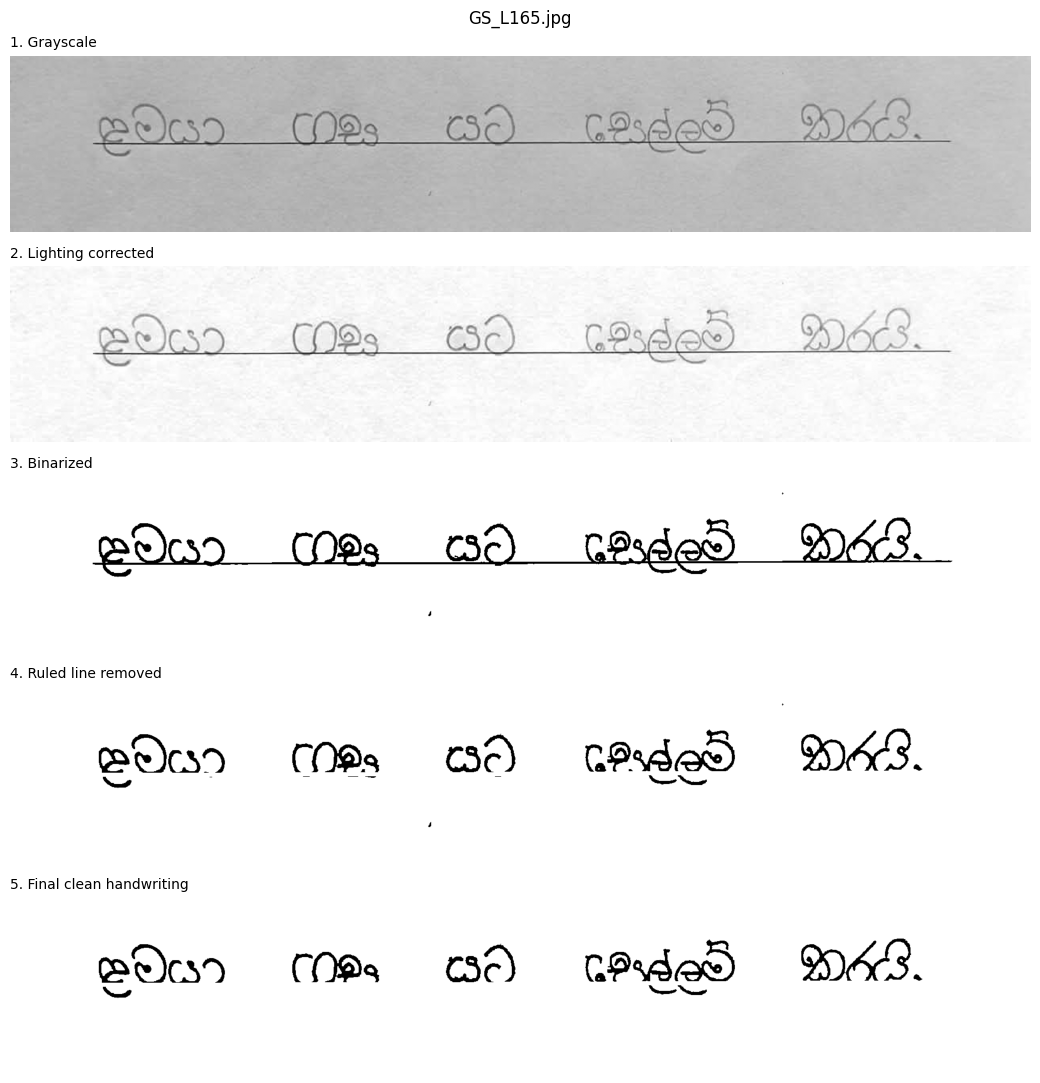

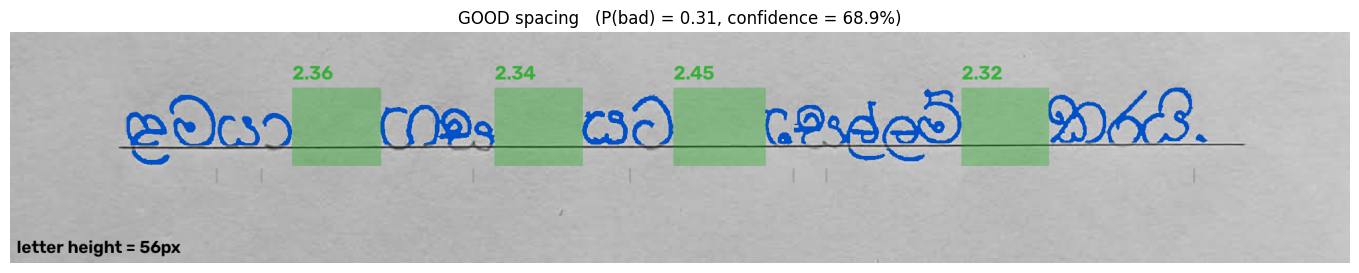

Prediction: GOOD spacing
Probability of bad spacing: 0.311
Letter height: 56px   Words found: 5
Normal word gap: 0.56 – 3.12 x letter height
  gap 1 (between word 1 and 2): 2.36 x letter height — ok
  gap 2 (between word 2 and 3): 2.34 x letter height — ok
  gap 3 (between word 3 and 4): 2.45 x letter height — ok
  gap 4 (between word 4 and 5): 2.32 x letter height — ok


In [ ]:
# ===== 9. PREDICT A NEW HANDWRITING IMAGE =====
# Run this cell and click "Choose Files" to upload one or more line images from your computer.
# (Sections 1 and 3-5 must have been run first, so the preprocessing functions exist.
#  The model is loaded from Drive, so you do NOT need to retrain.)
from google.colab import files
import joblib

def predict_image(path, bundle):
    """Classify one line image; show preprocessing and which word gaps are too wide / too narrow."""
    m = measure_line(path)
    f = pd.DataFrame([make_features(m)])[bundle['features']]
    p_bad = float(bundle['model'].predict_proba(f)[0, 1])
    verdict = 'BAD spacing' if p_bad > 0.5 else 'GOOD spacing'
    lo, hi = bundle['good_range']

    show_steps(m, os.path.basename(path))
    show(draw_gaps(m, bundle['good_range']),
         f'{verdict}   (P(bad) = {p_bad:.2f}, confidence = {max(p_bad, 1 - p_bad) * 100:.1f}%)')
    print(f'Prediction: {verdict}')
    print(f'Probability of bad spacing: {p_bad:.3f}')
    print(f'Letter height: {m["h"]:.0f}px   Words found: {len(m["words"])}')
    print(f'Normal word gap: {lo:.2f} – {hi:.2f} x letter height')
    for i, g in enumerate(m['gap_w'][m['is_word']], 1):
        note = 'TOO WIDE' if g > hi else 'TOO NARROW' if g < lo else 'ok'
        print(f'  gap {i} (between word {i} and {i + 1}): {g:.2f} x letter height — {note}')
    return verdict, p_bad

bundle = joblib.load(os.path.join(OUT_DIR, 'spacing_rf.joblib'))
print('Loaded model:', bundle['model_name'])

uploaded = files.upload()          # images are saved into /content
for name in uploaded:
    print('\n' + '=' * 70)
    try:
        predict_image(os.path.join('/content', name), bundle)
    except Exception as e:
        print(f'Could not process {name}: {e}')

# To predict an image that is already in Google Drive instead, use:
# predict_image('/content/drive/MyDrive/path/to/image.jpg', bundle)